# Consolidated statistical analysis pipeline — liver CT report LLM benchmark

## 1. Imports

In [1]:
from pathlib import Path
from itertools import combinations
import json
import re
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (
    cohen_kappa_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

## 2. Configuration

In [2]:
GROUND_TRUTH_PATH = Path("ground_truth_labels.xlsx")
MODEL_PATHS = {
    "GPT-4o": Path("CTliverlabelsSept2025_Val_Openai_4o.csv"),
    "GPT-5.6-Luna": Path("CTliverlabelsSept2025_Val_Openai_Luna.csv"),
    "GPT-5.6-Sol": Path("CTliverlabelsSept2025_Val_Openai_Sol.csv"),
    "Claude-Haiku-4-5": Path("CTliverlabelsSept2025_Val_Anthropic_Haiku.csv"),
    "Claude-Sonnet-5-5": Path("CTliverlabelsSept2025_Val_Anthropic_Sonnet5.csv"),
    "Claude-Opus-5-5": Path("CTliverlabelsSept2025_Val_Anthropic_Opus5.csv"),
    "Jev": Path("jev_liver_labels_V2.csv"),
}

RADIOLOGIST_PATHS = {
    "Radiologist 1": Path("ground_truth_labels_Dr1.xlsx"),
    "Radiologist 2": Path("ground_truth_labels_Dr2.xlsx"),
}

ID_COLUMN = "report_id"
OUTPUT_DIR = Path("paper_results_consolidated")
N_BOOTSTRAP = 2000
N_PERMUTATIONS = 2000
RANDOM_SEED = 42


CATEGORICAL_FIELDS = [
    "liver_status",
    "liver_malignancy_status",
    "liver_malignancy_level",
    "liver_steatosis",
    "liver_cirrhosis",
    "hepatomegaly",
    "liver_vascular_disease",
    "liver_calcification",
    "intrahepatic_duct_dilation",
    "further_exam_required",
    "liver_vague_multiple_present",
]
NUMERIC_FIELD = "liver_lesions_count"
ALL_FIELDS = CATEGORICAL_FIELDS + [NUMERIC_FIELD]
MODEL_ORDER = list(MODEL_PATHS)
CONSENSUS_MODEL_ORDER = [model for model in MODEL_ORDER]

ONTOLOGY = {
    "liver_status": {"normal", "abnormal", "not_mentioned"},
    "liver_malignancy_status": {"malignant", "not_malignant", "not_mentioned"},
    "liver_malignancy_level": {"primary", "secondary", "not_mentioned"},
    "liver_steatosis": {"y", "n"},
    "liver_cirrhosis": {"y", "n"},
    "hepatomegaly": {"y", "n"},
    "liver_vascular_disease": {"y", "n"},
    "liver_calcification": {"y", "n"},
    "intrahepatic_duct_dilation": {"y", "n"},
    "further_exam_required": {"y", "n"},
    "liver_vague_multiple_present": {"y", "n"},
}

POSITIVE_CLASS = {
    "liver_status": "abnormal",
    "liver_malignancy_status": "malignant",
    "liver_steatosis": "y",
    "liver_cirrhosis": "y",
    "hepatomegaly": "y",
    "liver_vascular_disease": "y",
    "liver_calcification": "y",
    "intrahepatic_duct_dilation": "y",
    "further_exam_required": "y",
    "liver_vague_multiple_present": "y",
}

## 3. Loading, normalization, and strict validation

In [3]:
PREFIX_PATTERN = re.compile(
    r"^(openai|anthropic|claude|gemini|jev|ground[_-]?truth|gt|truth)_+",
    re.IGNORECASE,
)


def normalize_column(column):
    return PREFIX_PATTERN.sub("", str(column)).strip().lower()


def normalize_value(value):
    if pd.isna(value):
        return ""
    text = str(value).strip().lower()
    text = re.sub(r"[\s-]+", "_", text)
    aliases = {
        "not_malignant": "not_malignant",
        "notmalignant": "not_malignant",
        "not_mentioned": "not_mentioned",
        "notmentioned": "not_mentioned",
        "yes": "y",
        "no": "n",
    }
    return aliases.get(text, text)


def parse_count(value):
    """Parse a lesion count without ever silently converting blank/null to zero."""
    if pd.isna(value):
        return np.nan
    text = str(value).strip().lower()
    if text in {"", "none", "null", "nan", "na", "n/a"}:
        return np.nan
    try:
        number = float(text)
    except ValueError:
        return np.nan
    if number < 0 or not float(number).is_integer():
        return np.nan
    return float(number)


def read_table(path):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"Input file not found: {path}")
    frame = pd.read_csv(path) if path.suffix.lower() == ".csv" else pd.read_excel(path)
    frame = frame.rename(columns={c: normalize_column(c) for c in frame.columns})
    id_col = normalize_column(ID_COLUMN)
    if id_col not in frame.columns:
        raise ValueError(f"{ID_COLUMN!r} not found in {path}. Columns: {list(frame.columns)}")
    frame[id_col] = frame[id_col].astype(str).str.strip()
    if frame[id_col].duplicated().any():
        dup = frame.loc[frame[id_col].duplicated(), id_col].tolist()[:10]
        raise ValueError(f"Duplicate report IDs in {path}: {dup}")
    return frame.set_index(id_col, drop=False)


def require_fields(frame, source_name, required_fields=None):
    fields = ALL_FIELDS if required_fields is None else required_fields
    missing = [f for f in fields if f not in frame.columns]
    if missing:
        raise ValueError(f"{source_name} is missing required fields: {missing}")


def validate_categorical_values(frame, source_name):
    problems = []
    for field in CATEGORICAL_FIELDS:
        values = frame[field].map(normalize_value)
        missing_n = int((values == "").sum())
        invalid = sorted(set(values) - ONTOLOGY[field] - {""})
        if missing_n:
            problems.append({"source": source_name, "field": field, "issue": "missing", "n": missing_n, "values": ""})
        if invalid:
            problems.append({"source": source_name, "field": field, "issue": "invalid", "n": int(values.isin(invalid).sum()), "values": "; ".join(invalid)})
    return problems

In [4]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

ground_truth = read_table(GROUND_TRUTH_PATH)
require_fields(ground_truth, "Ground truth")

evaluation_ids = ground_truth.index.tolist()

models = {}
validation_rows = []
validation_rows.extend(validate_categorical_values(ground_truth, "Ground truth"))

for model, path in MODEL_PATHS.items():
    frame = read_table(path)
    require_fields(frame, model, ALL_FIELDS)
    missing_ids = sorted(set(evaluation_ids) - set(frame.index))
    if missing_ids:
        raise ValueError(f"{model} is missing {len(missing_ids)} evaluation reports; examples: {missing_ids[:10]}")
    extra_ids = sorted(set(frame.index) - set(evaluation_ids))
    if extra_ids:
        print(f"Note: {model} has {len(extra_ids)} extra IDs not in ground truth; they will be ignored.")
    frame = frame.reindex(evaluation_ids) #reordering to match ground truth
    models[model] = frame
    validation_rows.extend(validate_categorical_values(frame, model))

validation_issues = pd.DataFrame(validation_rows)
if not validation_issues.empty:
    validation_issues.to_csv(OUTPUT_DIR / "data_validation_issues.csv", index=False)
    display(validation_issues)

# Ground-truth ontology problems invalidate the reference standard and therefore stop analysis.
if not validation_issues.empty:
    gt_issues = validation_issues[validation_issues["source"] == "Ground truth"]
    if not gt_issues.empty:
        raise ValueError(
            "Missing or invalid categorical labels were detected in the ground truth. "
            "Reference labels must be corrected before analysis."
        )

# Model ontology failures are genuine model errors. They are logged and converted to a
# dedicated sentinel so they count as incorrect without stopping the pipeline.
INVALID_PREDICTION = "__invalid__"

# Normalize categorical values once.
gt_cat = pd.DataFrame(index=evaluation_ids)
for field in CATEGORICAL_FIELDS:
    gt_cat[field] = ground_truth[field].map(normalize_value)

pred_cat = {}
invalid_prediction_rows = []

for model, frame in models.items():
    p = pd.DataFrame(index=evaluation_ids)

    # 1. Validate individual categorical values
    for field in CATEGORICAL_FIELDS:
        values = frame[field].map(normalize_value)
        invalid_mask = (values == "") | (~values.isin(ONTOLOGY[field]))

        if invalid_mask.any():
            for report_id in values.index[invalid_mask]:
                invalid_prediction_rows.append({
                    "model": model,
                    "report_id": report_id,
                    "field": field,
                    "raw_value": frame.loc[report_id, field],
                    "normalized_value": values.loc[report_id],
                    "reason": "invalid_or_missing_value",
                })

            values = values.mask(invalid_mask, INVALID_PREDICTION)

        p[field] = values

    pred_cat[model] = p

invalid_predictions = pd.DataFrame(invalid_prediction_rows)
invalid_predictions.to_csv(OUTPUT_DIR / "invalid_model_predictions.csv", index=False)
if not invalid_predictions.empty:
    print(f"Logged {len(invalid_predictions)} invalid/missing categorical model outputs; these count as incorrect.")
    display(invalid_predictions)

# Numeric count stays numeric and preserves null/unquantifiable as NaN.
gt_count = ground_truth[NUMERIC_FIELD].map(parse_count)
COUNT_MODEL_ORDER = MODEL_ORDER.copy()  # All seven models, including Jev, now provide lesion counts
pred_count = {model: models[model][NUMERIC_FIELD].map(parse_count) for model in COUNT_MODEL_ORDER}

count_diagnostic = pd.DataFrame([
    {
        "source": "Ground truth" if model is None else model,
        "n_reports": len(evaluation_ids),
        "n_numeric": int(series.notna().sum()),
        "n_missing_or_unparseable": int(series.isna().sum()),
        "n_zero": int(series.eq(0).sum()),
        "n_positive": int(series.gt(0).sum()),
    }
    for model, series in [(None, gt_count)] + list(pred_count.items())
])
count_diagnostic.to_csv(OUTPUT_DIR / "lesion_count_missingness_diagnostic.csv", index=False)

## 4. Metric helpers

In [5]:
def classes_in_reference(series):
    return sorted(pd.unique(pd.Series(series)))


def encode_field(field):
    # {'abnormal': 0, 'normal': 1, 'not_mentioned': 2}
    labels = classes_in_reference(gt_cat[field])
    mapping = {label: i for i, label in enumerate(labels)}
    invalid_code = len(labels)  # outside the valid reference classes
    gt_codes = gt_cat[field].map(mapping).to_numpy(dtype=np.int16)
    pred_codes = {}
    for model in MODEL_ORDER:
        mapped = pred_cat[model][field].map(mapping)
        pred_codes[model] = mapped.fillna(invalid_code).to_numpy(dtype=np.int16)
    return labels, mapping, gt_codes, pred_codes


ENCODED = {}
for field in CATEGORICAL_FIELDS:
    labels, mapping, gt_codes, pred_codes = encode_field(field)
    ENCODED[field] = {
        "labels": labels,
        "mapping": mapping,
        "gt": gt_codes,
        "pred": pred_codes,
        "k": len(labels),
    }
    

N_REPORTS = len(evaluation_ids)
rng_boot = np.random.default_rng(RANDOM_SEED)
BOOTSTRAP_INDEX = rng_boot.integers(0, N_REPORTS, size=(N_BOOTSTRAP, N_REPORTS), dtype=np.int32)


def point_metrics_codes(gt_codes, pred_codes, k):
    """Compute macro recall and macro F1 across the k reference classes."""
    recalls, f1s = [], []
    for cls in range(k):
        true_mask = gt_codes == cls
        n_true = true_mask.sum()
        if n_true == 0:
            return np.nan, np.nan
        tp = np.sum(true_mask & (pred_codes == cls))
        fp = np.sum((gt_codes != cls) & (pred_codes == cls))
        fn = np.sum(true_mask & (pred_codes != cls))
        recalls.append(tp / n_true)
        denom = 2 * tp + fp + fn
        f1s.append((2 * tp / denom) if denom else 0.0)
    return float(np.mean(recalls)), float(np.mean(f1s))


def bootstrap_field_metrics_codes(gt_codes, pred_codes, k, boot_idx=BOOTSTRAP_INDEX):
    """Compute bootstrap macro recall and F1, returning NaN when a class is absent."""
    g = gt_codes[boot_idx]
    p = pred_codes[boot_idx]
    recall_cols, f1_cols, present_cols = [], [], []
    for cls in range(k):
        true_mask = g == cls
        pred_mask = p == cls
        n_true = true_mask.sum(axis=1)
        tp = (true_mask & pred_mask).sum(axis=1)
        fp = ((~true_mask) & pred_mask).sum(axis=1)
        fn = (true_mask & (~pred_mask)).sum(axis=1)
        recall = np.divide(tp, n_true, out=np.full_like(tp, np.nan, dtype=float), where=n_true > 0)
        denom = 2 * tp + fp + fn
        f1 = np.divide(2 * tp, denom, out=np.zeros_like(tp, dtype=float), where=denom > 0)
        recall_cols.append(recall)
        f1_cols.append(f1)
        present_cols.append(n_true > 0)
    recalls = np.vstack(recall_cols).T
    f1s = np.vstack(f1_cols).T
    all_present = np.vstack(present_cols).T.all(axis=1)
    ba = recalls.mean(axis=1)
    mf1 = f1s.mean(axis=1)
    ba[~all_present] = np.nan
    mf1[~all_present] = np.nan
    return ba, mf1


def percentile_ci(estimates, alpha=0.05):
    """Return percentile CI bounds after excluding non-finite estimates."""
    estimates = np.asarray(estimates, dtype=float)
    estimates = estimates[np.isfinite(estimates)]
    if len(estimates) == 0:
        return np.nan, np.nan
    return tuple(np.quantile(estimates, [alpha / 2, 1 - alpha / 2]))


def fmt(est, lo, hi, digits=3):
    if not np.isfinite(est):
        return "NA"
    return f"{est:.{digits}f} ({lo:.{digits}f}–{hi:.{digits}f})"


FIELD_BOOT = {}
for field in CATEGORICAL_FIELDS:
    info = ENCODED[field]
    for model in MODEL_ORDER:
        ba_boot, f1_boot = bootstrap_field_metrics_codes(
            info["gt"], info["pred"][model], info["k"]
        )
        FIELD_BOOT[(field, model)] = {"balanced_accuracy": ba_boot, "macro_f1": f1_boot}


def overall_point_metric(model, metric_name):
    """Return the selected metric averaged equally across categorical fields."""
    values = []
    for field in CATEGORICAL_FIELDS:
        info = ENCODED[field]
        ba, mf1 = point_metrics_codes(info["gt"], info["pred"][model], info["k"])
        values.append(ba if metric_name == "balanced_accuracy" else mf1)
    return float(np.mean(values))


def overall_boot_distribution(model, metric_name):
    """Average valid field-level bootstrap estimates into an overall distribution."""
    matrix = np.vstack([FIELD_BOOT[(field, model)][metric_name] for field in CATEGORICAL_FIELDS])
    valid = np.isfinite(matrix).all(axis=0)
    out = np.full(matrix.shape[1], np.nan, dtype=float)
    out[valid] = matrix[:, valid].mean(axis=0)
    return out

def safe_eq(a, b):
    """
    Element-wise equality where missing values never count as agreement.

    Examples:
        "normal" == "normal"       -> True
        "normal" == "abnormal"     -> False
        NaN == NaN                 -> False
        None == None               -> False
    """
    a = pd.Series(a)
    b = pd.Series(b)

    return a.notna() & b.notna() & a.eq(b)

## 5. Main performance: model × categorical field

In [6]:
field_rows = []
for field in CATEGORICAL_FIELDS:
    info = ENCODED[field]
    for model in MODEL_ORDER:
        ba, mf1 = point_metrics_codes(info["gt"], info["pred"][model], info["k"])
        ba_boot = FIELD_BOOT[(field, model)]["balanced_accuracy"]
        f1_boot = FIELD_BOOT[(field, model)]["macro_f1"]
        ba_lo, ba_hi = percentile_ci(ba_boot)
        f1_lo, f1_hi = percentile_ci(f1_boot)
        field_rows.append({
            "field": field,
            "model": model,
            "n_reports": N_REPORTS,
            "n_classes": info["k"],
            "balanced_accuracy": ba,
            "ba_ci_low": ba_lo,
            "ba_ci_high": ba_hi,
            "ba_valid_bootstrap_replicates": int(np.isfinite(ba_boot).sum()),
            "macro_f1": mf1,
            "f1_ci_low": f1_lo,
            "f1_ci_high": f1_hi,
            "f1_valid_bootstrap_replicates": int(np.isfinite(f1_boot).sum()),
            "balanced_accuracy_95ci": fmt(ba, ba_lo, ba_hi),
            "macro_f1_95ci": fmt(mf1, f1_lo, f1_hi),
        })

field_performance = pd.DataFrame(field_rows)
field_performance.to_csv(OUTPUT_DIR / "table1_per_field_model_performance.csv", index=False)

## 6. Per-class precision, recall, and F1 with report-bootstrap 95% CIs

In [7]:
def per_class_point_and_boot(gt_codes, pred_codes, cls, boot_idx=BOOTSTRAP_INDEX):
    gt_pos = gt_codes == cls
    pred_pos = pred_codes == cls
    tp = np.sum(gt_pos & pred_pos)
    fp = np.sum((~gt_pos) & pred_pos)
    fn = np.sum(gt_pos & (~pred_pos))
    recall = tp / (tp + fn) if (tp + fn) else np.nan
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    f1_denom = 2 * tp + fp + fn
    f1 = (2 * tp / f1_denom) if f1_denom else 0.0

    g = gt_pos[boot_idx]
    p = pred_pos[boot_idx]
    tp_b = (g & p).sum(axis=1)
    fp_b = ((~g) & p).sum(axis=1)
    fn_b = (g & (~p)).sum(axis=1)
    n_true_b = tp_b + fn_b
    n_pred_b = tp_b + fp_b
    recall_b = np.divide(tp_b, n_true_b, out=np.full_like(tp_b, np.nan, dtype=float), where=n_true_b > 0)
    precision_b = np.divide(tp_b, n_pred_b, out=np.zeros_like(tp_b, dtype=float), where=n_pred_b > 0)
    f1_den_b = 2 * tp_b + fp_b + fn_b
    f1_b = np.divide(2 * tp_b, f1_den_b, out=np.zeros_like(tp_b, dtype=float), where=f1_den_b > 0)
    # A class absent from a bootstrap sample has no estimable class-specific metric.
    precision_b[n_true_b == 0] = np.nan
    f1_b[n_true_b == 0] = np.nan
    return (recall, precision, f1), (recall_b, precision_b, f1_b)


per_class_rows = []

for field in CATEGORICAL_FIELDS:
    info = ENCODED[field]

    for cls, class_label in enumerate(info["labels"]):
        n_class = int(np.sum(info["gt"] == cls))

        for model in MODEL_ORDER:
            point, boots = per_class_point_and_boot(
                info["gt"],
                info["pred"][model],
                cls
            )

            recall, precision, f1 = point
            recall_b, precision_b, f1_b = boots

            recall_lo, recall_hi = percentile_ci(recall_b)
            precision_lo, precision_hi = percentile_ci(precision_b)
            f1_lo, f1_hi = percentile_ci(f1_b)

            row = {
                "field": field,
                "class": class_label,
                "model": model,
                "n_reference": n_class,

                "recall": recall,
                "recall_ci_low": recall_lo,
                "recall_ci_high": recall_hi,
                "recall_95ci": fmt(recall, recall_lo, recall_hi),

                "precision": precision,
                "precision_ci_low": precision_lo,
                "precision_ci_high": precision_hi,
                "precision_95ci": fmt(
                    precision,
                    precision_lo,
                    precision_hi
                ),

                "f1": f1,
                "f1_ci_low": f1_lo,
                "f1_ci_high": f1_hi,
                "f1_95ci": fmt(f1, f1_lo, f1_hi),

                "recall_valid_bootstrap_replicates": int(
                    np.isfinite(recall_b).sum()
                ),
                "precision_valid_bootstrap_replicates": int(
                    np.isfinite(precision_b).sum()
                ),
                "f1_valid_bootstrap_replicates": int(
                    np.isfinite(f1_b).sum()
                ),
            }

            per_class_rows.append(row)

per_class_metrics = pd.DataFrame(per_class_rows)

per_class_metrics.to_csv(
    OUTPUT_DIR / "supplement_per_class_metrics.csv",
    index=False
)

## 7. Clinical positive-class sensitivity and specificity

In [8]:
def sens_spec_point_and_boot(gt_codes, pred_codes, positive_code, boot_idx=BOOTSTRAP_INDEX):
    gt_pos = gt_codes == positive_code
    pred_pos = pred_codes == positive_code
    sens = np.mean(pred_pos[gt_pos]) if gt_pos.sum() else np.nan
    spec = np.mean(~pred_pos[~gt_pos]) if (~gt_pos).sum() else np.nan

    g = gt_pos[boot_idx]
    p = pred_pos[boot_idx]
    tp = (g & p).sum(axis=1)
    tn = ((~g) & (~p)).sum(axis=1)
    n_pos = g.sum(axis=1)
    n_neg = (~g).sum(axis=1)
    sens_b = np.divide(tp, n_pos, out=np.full_like(tp, np.nan, dtype=float), where=n_pos > 0)
    spec_b = np.divide(tn, n_neg, out=np.full_like(tn, np.nan, dtype=float), where=n_neg > 0)
    return float(sens), float(spec), sens_b, spec_b


clinical_rows = []
for field, positive in POSITIVE_CLASS.items():
    info = ENCODED[field]
    positive_code = info["mapping"][positive]
    for model in MODEL_ORDER:
        sens, spec, sens_b, spec_b = sens_spec_point_and_boot(
            info["gt"], info["pred"][model], positive_code
        )
        sens_lo, sens_hi = percentile_ci(sens_b)
        spec_lo, spec_hi = percentile_ci(spec_b)
        clinical_rows.append({
            "field": field,
            "positive_class": positive,
            "model": model,
            "n_positive": int(np.sum(info["gt"] == positive_code)),
            "n_negative": int(np.sum(info["gt"] != positive_code)),
            "sensitivity": sens,
            "sensitivity_ci_low": sens_lo,
            "sensitivity_ci_high": sens_hi,
            "specificity": spec,
            "specificity_ci_low": spec_lo,
            "specificity_ci_high": spec_hi,
            "sensitivity_95ci": fmt(sens, sens_lo, sens_hi),
            "specificity_95ci": fmt(spec, spec_lo, spec_hi),
        })

clinical_performance = pd.DataFrame(clinical_rows)
clinical_performance.to_csv(OUTPUT_DIR / "table2_clinical_sensitivity_specificity.csv", index=False)

In [9]:

# ============================================================
# POSITIVE-CLASS PERFORMANCE
# Balanced Accuracy and F1 per model and clinical field
# 95% report-level bootstrap confidence intervals
# ============================================================
'''
The new section calculates, for each model and each positive clinical field:
- Balanced Accuracy = (Sensitivity + Specificity) / 2
- F1 Score = 2TP / (2TP + FP + FN)
- 95% bootstrap confidence intervals for both metrics, using your existing 2,000 report-level bootstrap samples.
- TP, TN, FP, FN and the number of positive ground-truth reports.
'''
VALID_POSITIVE_FIELDS = {
    field: positive_class
    for field, positive_class in POSITIVE_CLASS.items()
    if (
        positive_class is not None
        and field in ENCODED
        and positive_class in ENCODED[field]["mapping"]
    )
}

print(
    f"Analyzing {len(VALID_POSITIVE_FIELDS)} "
    f"positive clinical fields."
)

positive_rows = []

for field, positive_class in VALID_POSITIVE_FIELDS.items():

    info = ENCODED[field]
    positive_code = info["mapping"][positive_class]

    gt_pos = info["gt"] == positive_code

    for model in MODEL_ORDER:

        pred_pos = info["pred"][model] == positive_code

        tp = int(np.sum(gt_pos & pred_pos))
        tn = int(np.sum(~gt_pos & ~pred_pos))
        fp = int(np.sum(~gt_pos & pred_pos))
        fn = int(np.sum(gt_pos & ~pred_pos))

        n_positive = tp + fn
        n_negative = tn + fp

        sensitivity = (
            tp / n_positive if n_positive > 0 else np.nan
        )
        specificity = (
            tn / n_negative if n_negative > 0 else np.nan
        )

        balanced_accuracy = (
            (sensitivity + specificity) / 2
            if n_positive > 0 and n_negative > 0
            else np.nan
        )

        f1_denom = 2 * tp + fp + fn
        f1 = (
            2 * tp / f1_denom
            if f1_denom > 0 else 0.0
        )

        g = gt_pos[BOOTSTRAP_INDEX]
        p = pred_pos[BOOTSTRAP_INDEX]

        tp_b = (g & p).sum(axis=1)
        tn_b = (~g & ~p).sum(axis=1)
        fp_b = (~g & p).sum(axis=1)
        fn_b = (g & ~p).sum(axis=1)

        n_pos_b = tp_b + fn_b
        n_neg_b = tn_b + fp_b

        sensitivity_b = np.divide(
            tp_b,
            n_pos_b,
            out=np.full(N_BOOTSTRAP, np.nan),
            where=n_pos_b > 0,
        )

        specificity_b = np.divide(
            tn_b,
            n_neg_b,
            out=np.full(N_BOOTSTRAP, np.nan),
            where=n_neg_b > 0,
        )

        ba_b = (sensitivity_b + specificity_b) / 2

        f1_denom_b = 2 * tp_b + fp_b + fn_b

        f1_b = np.divide(
            2 * tp_b,
            f1_denom_b,
            out=np.zeros(N_BOOTSTRAP, dtype=float),
            where=f1_denom_b > 0,
        )


        f1_b[n_pos_b == 0] = np.nan

        ba_lo, ba_hi = percentile_ci(ba_b)
        f1_lo, f1_hi = percentile_ci(f1_b)

        positive_rows.append({
            "field": field,
            "positive_class": positive_class,
            "model": model,
            "n_reports": N_REPORTS,
            "n_positive": n_positive,
            "n_negative": n_negative,
            "TP": tp,
            "TN": tn,
            "FP": fp,
            "FN": fn,
            "balanced_accuracy": balanced_accuracy,
            "ba_ci_low": ba_lo,
            "ba_ci_high": ba_hi,
            "balanced_accuracy_95ci": fmt(
                balanced_accuracy, ba_lo, ba_hi
            ),
            "f1": f1,
            "f1_ci_low": f1_lo,
            "f1_ci_high": f1_hi,
            "f1_95ci": fmt(f1, f1_lo, f1_hi),
            "ba_valid_bootstrap_replicates": int(
                np.isfinite(ba_b).sum()
            ),
            "f1_valid_bootstrap_replicates": int(
                np.isfinite(f1_b).sum()
            ),
        })



positive_performance = pd.DataFrame(positive_rows)

positive_performance.to_csv(
    OUTPUT_DIR / "positive_class_balanced_accuracy_f1.csv",
    index=False
)

display(
    positive_performance[
        [
            "model",
            "field",
            "positive_class",
            "n_positive",
            "balanced_accuracy",
            "f1",
            "balanced_accuracy_95ci",
            "f1_95ci",
        ]
    ].round(4)
)



positive_ba_table = positive_performance.pivot(
    index="field",
    columns="model",
    values="balanced_accuracy",
).reindex(columns=MODEL_ORDER)

positive_f1_table = positive_performance.pivot(
    index="field",
    columns="model",
    values="f1",
).reindex(columns=MODEL_ORDER)

positive_ba_table.to_csv(
    OUTPUT_DIR / "positive_balanced_accuracy_by_field.csv"
)

positive_f1_table.to_csv(
    OUTPUT_DIR / "positive_f1_by_field.csv"
)

print("\nPOSITIVE-CLASS BALANCED ACCURACY")
display(positive_ba_table.round(3))

print("\nPOSITIVE-CLASS F1 SCORE")
display(positive_f1_table.round(3))



overall_rows = []
n_boot = BOOTSTRAP_INDEX.shape[0]

for model in MODEL_ORDER:

    ba_boot_fields = []
    f1_boot_fields = []

    for field, positive_class in VALID_POSITIVE_FIELDS.items():

        info = ENCODED[field]
        positive_code = info["mapping"][positive_class]

        gt_pos = np.asarray(info["gt"] == positive_code)
        pred_pos = np.asarray(
            info["pred"][model] == positive_code
        )

        # Same report-level resamples across models and fields
        g = gt_pos[BOOTSTRAP_INDEX]
        p = pred_pos[BOOTSTRAP_INDEX]

        tp = (g & p).sum(axis=1)
        tn = (~g & ~p).sum(axis=1)
        fp = (~g & p).sum(axis=1)
        fn = (g & ~p).sum(axis=1)

        n_pos = tp + fn
        n_neg = tn + fp

        sensitivity = np.divide(
            tp, n_pos,
            out=np.full(n_boot, np.nan),
            where=n_pos > 0
        )

        specificity = np.divide(
            tn, n_neg,
            out=np.full(n_boot, np.nan),
            where=n_neg > 0
        )

        ba_boot = (sensitivity + specificity) / 2

        f1_den = 2 * tp + fp + fn

        f1_boot = np.divide(
            2 * tp, f1_den,
            out=np.zeros(n_boot, dtype=float),
            where=f1_den > 0
        )

        # Match the original field-level methodology
        f1_boot[n_pos == 0] = np.nan

        ba_boot_fields.append(ba_boot)
        f1_boot_fields.append(f1_boot)

    # Each column represents one bootstrap replicate.
    ba_array = np.vstack(ba_boot_fields)
    f1_array = np.vstack(f1_boot_fields)

    # Mean across fields within each bootstrap replicate
    with np.errstate(invalid="ignore"):
        ba_counts = np.isfinite(ba_array).sum(axis=0)
        f1_counts = np.isfinite(f1_array).sum(axis=0)

        ba_boot_mean = np.divide(
            np.nansum(ba_array, axis=0),
            ba_counts,
            out=np.full(n_boot, np.nan),
            where=ba_counts > 0
        )

        f1_boot_mean = np.divide(
            np.nansum(f1_array, axis=0),
            f1_counts,
            out=np.full(n_boot, np.nan),
            where=f1_counts > 0
        )

    ba_lo, ba_hi = percentile_ci(ba_boot_mean)
    f1_lo, f1_hi = percentile_ci(f1_boot_mean)

    # Original point estimates from all reports
    model_rows = positive_performance[
        positive_performance["model"] == model
    ]

    mean_ba = model_rows["balanced_accuracy"].mean()
    mean_f1 = model_rows["f1"].mean()

    overall_rows.append({
        "model": model,
        "mean_balanced_accuracy": mean_ba,
        "ba_ci_low": ba_lo,
        "ba_ci_high": ba_hi,
        "mean_f1": mean_f1,
        "f1_ci_low": f1_lo,
        "f1_ci_high": f1_hi,
        "ba_valid_bootstrap": int(
            np.isfinite(ba_boot_mean).sum()
        ),
        "f1_valid_bootstrap": int(
            np.isfinite(f1_boot_mean).sum()
        )
    })

positive_overall = (
    pd.DataFrame(overall_rows)
    .sort_values(
        "mean_balanced_accuracy",
        ascending=False,
        na_position="last"
    )
    .reset_index(drop=True)
)

positive_overall.to_csv(
    OUTPUT_DIR / "positive_overall_model_performance_with_CI.csv",
    index=False
)


Analyzing 10 positive clinical fields.


,model,field,positive_class,n_positive,balanced_accuracy,f1,balanced_accuracy_95ci,f1_95ci
0,GPT-4o,liver_status,abnormal,136,0.9775,0.9742,0.978 (0.960–0.992),0.974 (0.953–0.991)
1,GPT-5.6-Luna,liver_status,abnormal,136,0.9760,0.9708,0.976 (0.959–0.991),0.971 (0.949–0.989)
2,GPT-5.6-Sol,liver_status,abnormal,136,0.9808,0.9747,0.981 (0.966–0.994),0.975 (0.954–0.992)
3,Claude-Haiku-4-5,liver_status,abnormal,136,0.9397,0.9344,0.940 (0.911–0.965),0.934 (0.901–0.963)
4,Claude-Sonnet-5-5,liver_status,abnormal,136,0.9760,0.9708,0.976 (0.958–0.991),0.971 (0.949–0.989)
...,...,...,...,...,...,...,...,...
65,GPT-5.6-Sol,liver_vague_multiple_present,y,29,0.9967,0.9667,0.997 (0.992–1.000),0.967 (0.909–1.000)
66,Claude-Haiku-4-5,liver_vague_multiple_present,y,29,0.8276,0.7917,0.828 (0.739–0.914),0.792 (0.647–0.906)
67,Claude-Sonnet-5-5,liver_vague_multiple_present,y,29,0.9639,0.9474,0.964 (0.911–1.000),0.947 (0.875–1.000)
68,Claude-Opus-5-5,liver_vague_multiple_present,y,29,0.9983,0.9831,0.998 (0.995–1.000),0.983 (0.938–1.000)



POSITIVE-CLASS BALANCED ACCURACY


model,GPT-4o,GPT-5.6-Luna,GPT-5.6-Sol,Claude-Haiku-4-5,Claude-Sonnet-5-5,Claude-Opus-5-5,Jev
field,,,,,,,
further_exam_required,0.765,0.907,0.938,0.851,0.820,0.851,0.794
hepatomegaly,0.998,1.000,0.998,0.975,0.998,0.998,0.998
intrahepatic_duct_dilation,0.950,0.951,0.974,0.932,0.951,0.989,0.930
liver_calcification,0.998,1.000,1.000,1.000,1.000,1.000,1.000
liver_cirrhosis,0.998,1.000,1.000,1.000,1.000,1.000,1.000
liver_malignancy_status,0.786,0.891,0.927,0.888,0.893,0.929,0.964
liver_status,0.978,0.976,0.981,0.940,0.976,0.981,0.970
liver_steatosis,1.000,0.998,1.000,1.000,1.000,1.000,1.000
liver_vague_multiple_present,0.943,0.947,0.997,0.828,0.964,0.998,0.995



POSITIVE-CLASS F1 SCORE


model,GPT-4o,GPT-5.6-Luna,GPT-5.6-Sol,Claude-Haiku-4-5,Claude-Sonnet-5-5,Claude-Opus-5-5,Jev
field,,,,,,,
further_exam_required,0.692,0.824,0.882,0.800,0.733,0.800,0.741
hepatomegaly,0.976,1.000,0.976,0.974,0.976,0.976,0.976
intrahepatic_duct_dilation,0.889,0.909,0.933,0.927,0.909,0.863,0.905
liver_calcification,0.952,1.000,1.000,1.000,1.000,1.000,1.000
liver_cirrhosis,0.857,1.000,1.000,1.000,1.000,1.000,1.000
liver_malignancy_status,0.727,0.846,0.889,0.786,0.880,0.923,0.963
liver_status,0.974,0.971,0.975,0.934,0.971,0.975,0.967
liver_steatosis,1.000,0.989,1.000,1.000,1.000,1.000,1.000
liver_vague_multiple_present,0.897,0.929,0.967,0.792,0.947,0.983,0.951


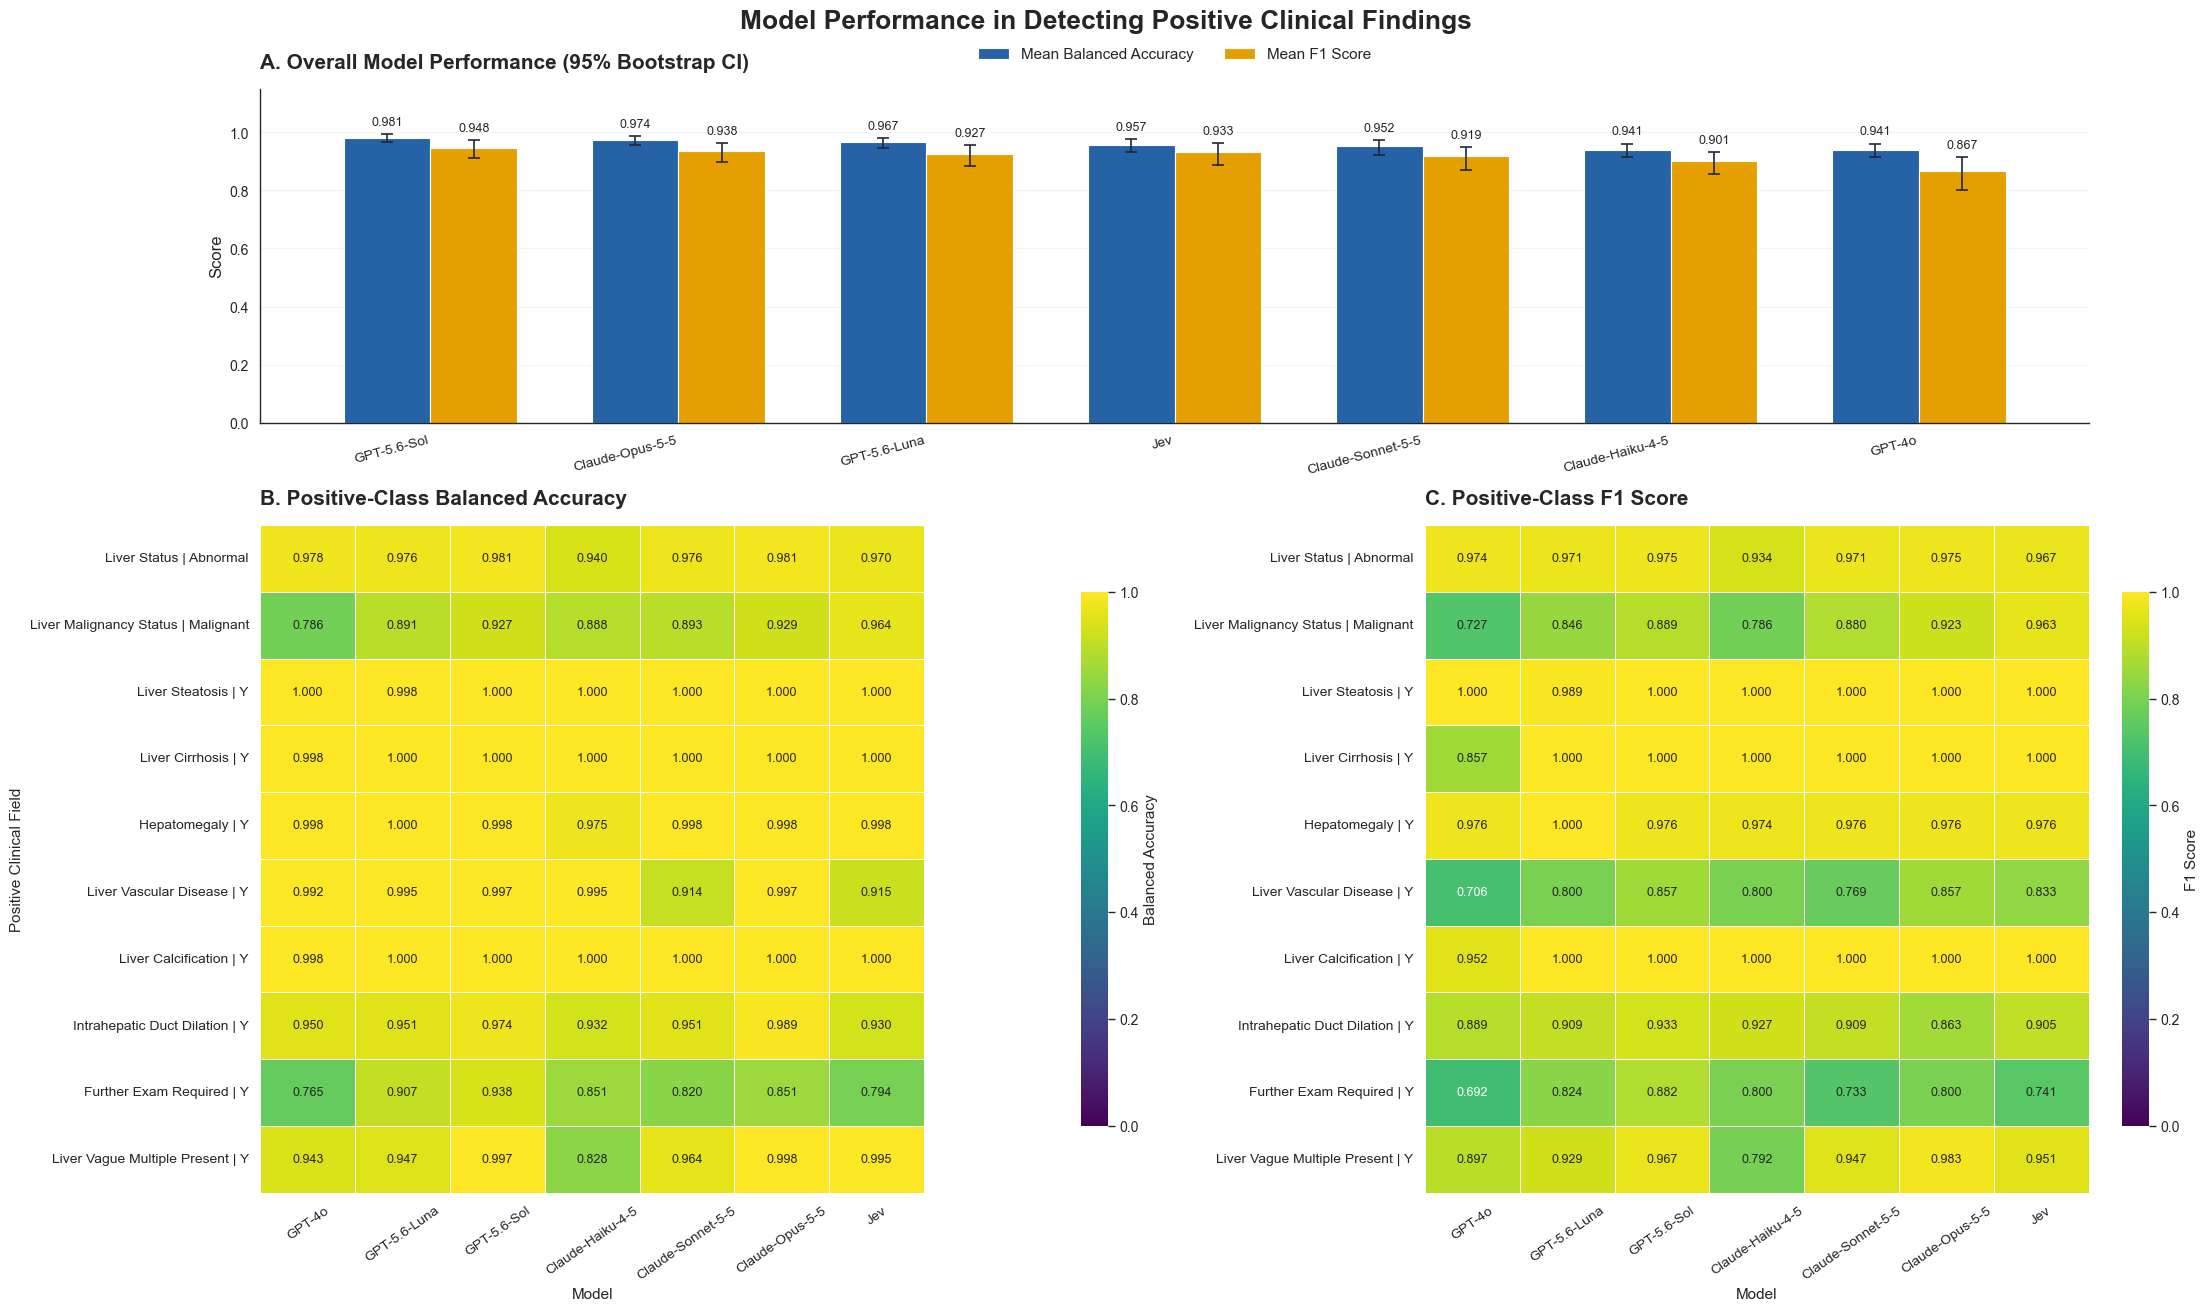

In [10]:

# ============================================================
# POSITIVE CLINICAL FIELD PERFORMANCE — 3-PANEL FIGURE
# A: Overall model performance
# B: Positive-class balanced accuracy by field and model
# C: Positive-class F1 score by field and model
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

sns.set_theme(style="white", context="paper", font_scale=1.15)



# Rank models by descending mean balanced accuracy
model_order = (
    positive_overall[
        positive_overall["model"].isin(MODEL_ORDER)
    ]
    .sort_values(
        by="mean_balanced_accuracy",
        ascending=False,
        na_position="last"
    )["model"]
    .tolist()
)

overall_plot = (
    positive_overall
    .set_index("model")
    .reindex(model_order)
)


heatmap_model_order = [
    m for m in MODEL_ORDER
    if m in positive_performance["model"].unique()
]

field_order = list(POSITIVE_CLASS.keys())

f1_plot = (
    positive_f1_table
    .reindex(
        index=field_order,
        columns=heatmap_model_order
    )
)

ba_plot = (
    positive_ba_table
    .reindex(
        index=field_order,
        columns=heatmap_model_order
    )
)



field_order = list(POSITIVE_CLASS.keys())

def format_positive_class(value):
    if isinstance(value, (set, list, tuple)):
        return " / ".join(
            str(v).replace("_", " ").title()
            for v in sorted(value)
        )
    if value is None:
        return "Not defined"
    return str(value).replace("_", " ").title()

field_labels = [
    (
        f"{field.replace('_', ' ').title()}"
        f" | {format_positive_class(POSITIVE_CLASS[field])}"
    )
    for field in field_order
]

# Apply to both heatmaps
f1_plot.index = field_labels
ba_plot.index = field_labels


fig = plt.figure(figsize=(22, 13), constrained_layout=True)

gs = fig.add_gridspec(
    nrows=2,
    ncols=2,
    height_ratios=[1, 2.0],
    width_ratios=[1, 1]
)

ax_a = fig.add_subplot(gs[0, :])
ax_b = fig.add_subplot(gs[1, 0])
ax_c = fig.add_subplot(gs[1, 1])

# Panel A

# Rank models from highest to lowest balanced accuracy
model_order = (
    positive_overall
    .sort_values(
        "mean_balanced_accuracy",
        ascending=False,
        na_position="last"
    )["model"]
    .tolist()
)

overall_plot = (
    positive_overall
    .set_index("model")
    .reindex(model_order)
)

x = np.arange(len(model_order))
bar_width = 0.35

ba_values = overall_plot[
    "mean_balanced_accuracy"
].to_numpy(dtype=float)

f1_values = overall_plot[
    "mean_f1"
].to_numpy(dtype=float)

# Asymmetric 95% CI error bars
ba_yerr = np.vstack([
    np.maximum(
        0, ba_values - overall_plot["ba_ci_low"].to_numpy()
    ),
    np.maximum(
        0, overall_plot["ba_ci_high"].to_numpy() - ba_values
    )
])

f1_yerr = np.vstack([
    np.maximum(
        0, f1_values - overall_plot["f1_ci_low"].to_numpy()
    ),
    np.maximum(
        0, overall_plot["f1_ci_high"].to_numpy() - f1_values
    )
])

bars_ba = ax_a.bar(
    x - bar_width / 2,
    ba_values,
    bar_width,
    yerr=ba_yerr,
    capsize=4,
    error_kw={
        "elinewidth": 1.2,
        "capthick": 1.2,
        "ecolor": "#1F2937"
    },
    color="#2563A6",
    label="Mean Balanced Accuracy"
)

bars_f1 = ax_a.bar(
    x + bar_width / 2,
    f1_values,
    bar_width,
    yerr=f1_yerr,
    capsize=4,
    error_kw={
        "elinewidth": 1.2,
        "capthick": 1.2,
        "ecolor": "#1F2937"
    },
    color="#E69F00",
    label="Mean F1 Score"
)

ax_a.set_xticks(x)
ax_a.set_xticklabels(
    model_order,
    fontsize=10,
    rotation=15,
    ha="right"
)

ax_a.set_ylabel("Score", fontsize=12)
ax_a.set_ylim(0, 1.15)

ax_a.set_title(
    "A. Overall Model Performance (95% Bootstrap CI)",
    fontsize=15,
    fontweight="bold",
    loc="left",
    pad=15
)

ax_a.legend(
    loc="lower center",
    bbox_to_anchor=(0.5, 1.04),
    frameon=False,
    ncol=2,
    fontsize=11
)

ax_a.spines["top"].set_visible(False)
ax_a.spines["right"].set_visible(False)

ax_a.grid(axis="y", alpha=0.2)
ax_a.set_axisbelow(True)


for bars, values, yerr in [
    (bars_ba, ba_values, ba_yerr),
    (bars_f1, f1_values, f1_yerr)
]:
    for i, bar in enumerate(bars):

        value = values[i]

        if np.isfinite(value):
            top = value + yerr[1, i]

            ax_a.text(
                bar.get_x() + bar.get_width() / 2,
                top + 0.02,
                f"{value:.3f}",
                ha="center",
                va="bottom",
                fontsize=9
            )


# Panel B

sns.heatmap(
    ba_plot,
    ax=ax_b,
    annot=True,
    fmt=".3f",
    cmap="viridis",
    vmin=0,
    vmax=1,
    linewidths=0.5,
    linecolor="white",
    cbar=True,
    cbar_kws={
        "label": "Balanced Accuracy",
        "shrink": 0.8
    },
    annot_kws={"fontsize": 9}
)

ax_b.set_title(
    "B. Positive-Class Balanced Accuracy",
    fontsize=15,
    fontweight="bold",
    loc="left",
    pad=15
)

ax_b.set_xlabel("Model", fontsize=11)
ax_b.set_ylabel("Positive Clinical Field", fontsize=11)

ax_b.tick_params(axis="x", rotation=35, labelsize=10)
ax_b.tick_params(axis="y", rotation=0, labelsize=10)

# PAnel C

sns.heatmap(
    f1_plot,
    ax=ax_c,
    annot=True,
    fmt=".3f",
    cmap="viridis",
    vmin=0,
    vmax=1,
    linewidths=0.5,
    linecolor="white",
    cbar=True,
    cbar_kws={
        "label": "F1 Score",
        "shrink": 0.8
    },
    annot_kws={"fontsize": 9}
)

ax_c.set_title(
    "C. Positive-Class F1 Score",
    fontsize=15,
    fontweight="bold",
    loc="left",
    pad=15
)

ax_c.set_xlabel("Model", fontsize=11)
ax_c.set_ylabel("")

ax_c.tick_params(axis="x", rotation=35, labelsize=10)
ax_c.tick_params(axis="y", rotation=0, labelsize=10)


fig.suptitle(
    "Model Performance in Detecting Positive Clinical Findings",
    fontsize=19,
    fontweight="bold"
)


fig.savefig(
    OUTPUT_DIR / "positive_clinical_performance_3panel.png",
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    OUTPUT_DIR / "positive_clinical_performance_3panel.pdf",
    bbox_inches="tight"
)

plt.show()


## 8. Field-averaged model performance

In [11]:
overall_boot = {}
overall_rows = []
for model in MODEL_ORDER:
    for metric_name in ["balanced_accuracy", "macro_f1"]:
        overall_boot[(model, metric_name)] = overall_boot_distribution(model, metric_name)

    ba = overall_point_metric(model, "balanced_accuracy")
    mf1 = overall_point_metric(model, "macro_f1")
    ba_boot = overall_boot[(model, "balanced_accuracy")]
    f1_boot = overall_boot[(model, "macro_f1")]
    ba_lo, ba_hi = percentile_ci(ba_boot)
    f1_lo, f1_hi = percentile_ci(f1_boot)
    overall_rows.append({
        "model": model,
        "n_reports": N_REPORTS,
        "n_categorical_fields": len(CATEGORICAL_FIELDS),
        "field_averaged_balanced_accuracy": ba,
        "ba_ci_low": ba_lo,
        "ba_ci_high": ba_hi,
        "ba_valid_bootstrap_replicates": int(np.isfinite(ba_boot).sum()),
        "field_averaged_macro_f1": mf1,
        "f1_ci_low": f1_lo,
        "f1_ci_high": f1_hi,
        "f1_valid_bootstrap_replicates": int(np.isfinite(f1_boot).sum()),
        "balanced_accuracy_95ci": fmt(ba, ba_lo, ba_hi),
        "macro_f1_95ci": fmt(mf1, f1_lo, f1_hi),
    })

overall_performance = pd.DataFrame(overall_rows).sort_values("field_averaged_balanced_accuracy", ascending=False)
overall_performance.to_csv(OUTPUT_DIR / "table3_overall_model_performance.csv", index=False)

## 9. Statistical significance: paired model comparisons (seven models)


In [12]:

# ============================================================
# 9. PAIRED MODEL COMPARISONS: EFFECT SIZE, 95% CI, P-VALUES
# Seven models × 11 categorical fields (21 pairs × 2 metrics)
# ============================================================

from itertools import combinations
import numpy as np
import pandas as pd

METRIC_NAMES = ("balanced_accuracy", "macro_f1")
SIGNIFICANCE_ALPHA = 0.05
N_PAIRWISE_PERMUTATIONS = 10000


def holm_adjust(p_values):
    """Holm step-down adjusted p-values, preserving NaNs."""
    values = np.asarray(p_values, dtype=float)
    adjusted = np.full(values.shape, np.nan, dtype=float)
    valid_idx = np.flatnonzero(np.isfinite(values))
    if len(valid_idx) == 0:
        return adjusted
    sorted_idx = valid_idx[np.argsort(values[valid_idx])]
    n = len(sorted_idx)
    step = values[sorted_idx] * np.arange(n, 0, -1)
    adjusted[sorted_idx] = np.clip(np.maximum.accumulate(step), 0, 1)
    return adjusted


def permuted_field_metric_differences(field, model_a, model_b, swap_mask):
    """
    Calculate model A - B (BA and macro F1), one value per permutation.

    swap_mask: shape (n_permutations, n_reports). The SAME report swap
    indicators must be used across all 11 fields for a model pair.
    """
    info = ENCODED[field]
    gt = np.asarray(info["gt"])
    a = np.asarray(info["pred"][model_a])
    b = np.asarray(info["pred"][model_b])
    k = int(info["k"])

    # Swap *whole-report* model labels, not individual field labels.
    a_perm = np.where(swap_mask, b[None, :], a[None, :])
    b_perm = np.where(swap_mask, a[None, :], b[None, :])
    n_perm = swap_mask.shape[0]
    ba_diff = np.zeros(n_perm, dtype=float)
    f1_diff = np.zeros(n_perm, dtype=float)

    for cls in range(k):
        reference_pos = (gt == cls)[None, :]
        n_true = int(reference_pos.sum())
        if n_true == 0:
            raise ValueError(f"{field}: reference class {cls} has no examples")

        a_pos = a_perm == cls
        b_pos = b_perm == cls
        tp_a = (a_pos & reference_pos).sum(axis=1)
        tp_b = (b_pos & reference_pos).sum(axis=1)
        fp_a = (a_pos & ~reference_pos).sum(axis=1)
        fp_b = (b_pos & ~reference_pos).sum(axis=1)
        fn_a = n_true - tp_a
        fn_b = n_true - tp_b

        ba_diff += tp_a / n_true - tp_b / n_true

        denom_a = 2 * tp_a + fp_a + fn_a
        denom_b = 2 * tp_b + fp_b + fn_b
        f1_a = np.divide(2 * tp_a, denom_a, out=np.zeros(n_perm), where=denom_a > 0)
        f1_b = np.divide(2 * tp_b, denom_b, out=np.zeros(n_perm), where=denom_b > 0)
        f1_diff += f1_a - f1_b

    return ba_diff / k, f1_diff / k



permutation_rng = np.random.default_rng(RANDOM_SEED + 1009)
swap_mask = permutation_rng.integers(
    0, 2, size=(N_PAIRWISE_PERMUTATIONS, N_REPORTS), dtype=np.int8
).astype(bool)

pairwise_rows = []
for model_a, model_b in combinations(MODEL_ORDER, 2):
    observed = {
        metric: overall_point_metric(model_a, metric) - overall_point_metric(model_b, metric)
        for metric in METRIC_NAMES
    }

    # Compute permutation null differences, preserving all 11 fields per report.
    perm_ba = np.zeros(N_PAIRWISE_PERMUTATIONS, dtype=float)
    perm_f1 = np.zeros(N_PAIRWISE_PERMUTATIONS, dtype=float)
    for field in CATEGORICAL_FIELDS:
        field_ba, field_f1 = permuted_field_metric_differences(
            field, model_a, model_b, swap_mask
        )
        perm_ba += field_ba / len(CATEGORICAL_FIELDS)
        perm_f1 += field_f1 / len(CATEGORICAL_FIELDS)

    null_distributions = {
        "balanced_accuracy": perm_ba,
        "macro_f1": perm_f1,
    }

    for metric in METRIC_NAMES:
        bootstrap_diff = (
            np.asarray(overall_boot[(model_a, metric)])
            - np.asarray(overall_boot[(model_b, metric)])
        )
        ci_lo, ci_hi = percentile_ci(bootstrap_diff)
        n_valid = int(np.isfinite(bootstrap_diff).sum())

        null_diff = null_distributions[metric]
        valid_null = null_diff[np.isfinite(null_diff)]
        if len(valid_null) == 0:
            p_value = np.nan
        else:
            p_value = (
                1 + np.count_nonzero(
                    np.abs(valid_null) >= (abs(observed[metric]) - 1e-12)
                )
            ) / (len(valid_null) + 1)

        pairwise_rows.append({
            "metric": metric,
            "model_a": model_a,
            "model_b": model_b,
            "difference_a_minus_b": observed[metric],
            "difference_ci_low": ci_lo,
            "difference_ci_high": ci_hi,
            "difference_95ci": fmt(observed[metric], ci_lo, ci_hi),
            "permutation_p_two_sided": p_value,
            "valid_paired_bootstrap_replicates": n_valid,
            "permutations": len(valid_null),
            "n_reports": N_REPORTS,
            "n_fields": len(CATEGORICAL_FIELDS),
        })

pairwise_significance = pd.DataFrame(pairwise_rows)


pairwise_significance["holm_p_within_metric"] = np.nan
for metric in METRIC_NAMES:
    mask = pairwise_significance["metric"].eq(metric)
    pairwise_significance.loc[mask, "holm_p_within_metric"] = holm_adjust(
        pairwise_significance.loc[mask, "permutation_p_two_sided"].to_numpy()
    )

pairwise_significance["holm_p_all_42_tests"] = holm_adjust(
    pairwise_significance["permutation_p_two_sided"].to_numpy()
)
pairwise_significance["significant_holm_within_metric"] = (
    pairwise_significance["holm_p_within_metric"] < SIGNIFICANCE_ALPHA
)

pairwise_significance = pairwise_significance.sort_values(
    ["metric", "holm_p_within_metric", "permutation_p_two_sided"]
).reset_index(drop=True)

output_path = OUTPUT_DIR / "table_pairwise_model_significance_7models.csv"
pairwise_significance.to_csv(output_path, index=False)


## 10. Numeric lesion-count performance

In [13]:
# ============================================================
# LESION COUNT PERFORMANCE — ALL SEVEN MODELS, INCLUDING JEV
# ============================================================

gt_count_arr = gt_count.to_numpy(dtype=float)

COUNT_GROUPS = {
    "gt0": {
        "mask": np.isfinite(gt_count_arr) & (gt_count_arr == 0),
        "label": "GT = 0",
        "filename": "table5_lesion_count_performance_gt0.csv",
    },
    "gt_positive": {
        "mask": np.isfinite(gt_count_arr) & (gt_count_arr > 0),
        "label": "GT > 0",
        "filename": "table5_lesion_count_performance_gt_positive.csv",
    },
}

count_tables = {}

for group_name, group_info in COUNT_GROUPS.items():
    group_mask = group_info["mask"]
    n_group = int(group_mask.sum())
    print(f"\n{'=' * 60}")
    print(f"LESION COUNT PERFORMANCE — {group_info['label']}")
    print(f"{'=' * 60}")
    print(f"Reports: {n_group}/{N_REPORTS}")
    print(f"Prevalence: {n_group / N_REPORTS:.1%}")
    count_rows = []

    for model in COUNT_MODEL_ORDER:
        pred_arr = pred_count[model].to_numpy(dtype=float)
        valid_mask = group_mask & np.isfinite(pred_arr)
        n_valid = int(valid_mask.sum())
        coverage = n_valid / n_group if n_group else np.nan

        mae = (
            float(np.abs(gt_count_arr[valid_mask] - pred_arr[valid_mask]).mean())
            if n_valid else np.nan
        )

        exact_success = valid_mask & (gt_count_arr == pred_arr)
        exact = float(exact_success[group_mask].mean()) if n_group else np.nan

        gt_b = gt_count_arr[BOOTSTRAP_INDEX]
        pred_b = pred_arr[BOOTSTRAP_INDEX]
        group_b = group_mask[BOOTSTRAP_INDEX]
        valid_b = group_b & np.isfinite(pred_b)
        group_n_b = group_b.sum(axis=1)
        valid_n_b = valid_b.sum(axis=1)

        abs_error_b = np.where(valid_b, np.abs(gt_b - pred_b), 0.0)
        mae_boot = np.divide(
            abs_error_b.sum(axis=1), valid_n_b,
            out=np.full(N_BOOTSTRAP, np.nan), where=valid_n_b > 0,
        )
        exact_b = valid_b & (gt_b == pred_b)
        exact_boot = np.divide(
            exact_b.sum(axis=1), group_n_b,
            out=np.full(N_BOOTSTRAP, np.nan), where=group_n_b > 0,
        )
        coverage_boot = np.divide(
            valid_n_b, group_n_b,
            out=np.full(N_BOOTSTRAP, np.nan), where=group_n_b > 0,
        )

        mae_lo, mae_hi = percentile_ci(mae_boot)
        ex_lo, ex_hi = percentile_ci(exact_boot)
        cov_lo, cov_hi = percentile_ci(coverage_boot)

        count_rows.append({
            "model": model,
            "n_reports": n_group,
            "n_numeric_predictions": n_valid,
            "n_missing_predictions": n_group - n_valid,
            "numeric_coverage": coverage,
            "numeric_coverage_ci_low": cov_lo,
            "numeric_coverage_ci_high": cov_hi,
            "mae": mae,
            "mae_ci_low": mae_lo,
            "mae_ci_high": mae_hi,
            "exact_match": exact,
            "exact_match_ci_low": ex_lo,
            "exact_match_ci_high": ex_hi,
            "mae_95ci": fmt(mae, mae_lo, mae_hi),
            "exact_match_95ci": fmt(exact, ex_lo, ex_hi),
        })

    df = pd.DataFrame(count_rows)
    count_tables[group_name] = df
    df.to_csv(OUTPUT_DIR / group_info["filename"], index=False)
    display(df)

lesion_count_performance_gt0 = count_tables["gt0"]
lesion_count_performance_gt_positive = count_tables["gt_positive"]
lesion_count_performance_gt0_original = lesion_count_performance_gt_positive



LESION COUNT PERFORMANCE — GT = 0
Reports: 269/329
Prevalence: 81.8%


,model,n_reports,n_numeric_predictions,n_missing_predictions,numeric_coverage,numeric_coverage_ci_low,numeric_coverage_ci_high,mae,mae_ci_low,mae_ci_high,exact_match,exact_match_ci_low,exact_match_ci_high,mae_95ci,exact_match_95ci
0,GPT-4o,269,269,0,1.0,1.0,1.0,0.011152,0.000000,0.034351,0.996283,0.988550,1.000000,0.011 (0.000–0.034),0.996 (0.989–1.000)
1,GPT-5.6-Luna,269,269,0,1.0,1.0,1.0,0.011152,0.000000,0.034619,0.996283,0.988460,1.000000,0.011 (0.000–0.035),0.996 (0.988–1.000)
2,GPT-5.6-Sol,269,269,0,1.0,1.0,1.0,0.018587,0.000000,0.047450,0.988848,0.974167,1.000000,0.019 (0.000–0.047),0.989 (0.974–1.000)
3,Claude-Haiku-4-5,269,269,0,1.0,1.0,1.0,0.007435,0.000000,0.023079,0.996283,0.988460,1.000000,0.007 (0.000–0.023),0.996 (0.988–1.000)
4,Claude-Sonnet-5-5,269,269,0,1.0,1.0,1.0,0.014870,0.000000,0.042564,0.992565,0.981132,1.000000,0.015 (0.000–0.043),0.993 (0.981–1.000)
5,Claude-Opus-5-5,269,269,0,1.0,1.0,1.0,0.018587,0.000000,0.047450,0.988848,0.974167,1.000000,0.019 (0.000–0.047),0.989 (0.974–1.000)
6,Jev,269,269,0,1.0,1.0,1.0,0.029740,0.007352,0.060154,0.977695,0.959410,0.992727,0.030 (0.007–0.060),0.978 (0.959–0.993)



LESION COUNT PERFORMANCE — GT > 0
Reports: 60/329
Prevalence: 18.2%


,model,n_reports,n_numeric_predictions,n_missing_predictions,numeric_coverage,numeric_coverage_ci_low,numeric_coverage_ci_high,mae,mae_ci_low,mae_ci_high,exact_match,exact_match_ci_low,exact_match_ci_high,mae_95ci,exact_match_95ci
0,GPT-4o,60,60,0,1.0,1.0,1.0,0.100000,0.015385,0.230797,0.933333,0.862069,0.984848,0.100 (0.015–0.231),0.933 (0.862–0.985)
1,GPT-5.6-Luna,60,60,0,1.0,1.0,1.0,0.066667,0.014706,0.135612,0.933333,0.864388,0.985294,0.067 (0.015–0.136),0.933 (0.864–0.985)
2,GPT-5.6-Sol,60,60,0,1.0,1.0,1.0,0.016667,0.000000,0.056604,0.983333,0.943396,1.000000,0.017 (0.000–0.057),0.983 (0.943–1.000)
3,Claude-Haiku-4-5,60,60,0,1.0,1.0,1.0,0.100000,0.018519,0.203713,0.916667,0.836054,0.982143,0.100 (0.019–0.204),0.917 (0.836–0.982)
4,Claude-Sonnet-5-5,60,60,0,1.0,1.0,1.0,0.116667,0.037736,0.206363,0.883333,0.793637,0.962264,0.117 (0.038–0.206),0.883 (0.794–0.962)
5,Claude-Opus-5-5,60,60,0,1.0,1.0,1.0,0.016667,0.000000,0.057692,0.983333,0.942308,1.000000,0.017 (0.000–0.058),0.983 (0.942–1.000)
6,Jev,60,60,0,1.0,1.0,1.0,0.083333,0.000000,0.208358,0.950000,0.887097,1.000000,0.083 (0.000–0.208),0.950 (0.887–1.000)


### Lesion-count performance visualization — reference-standard zero vs positive


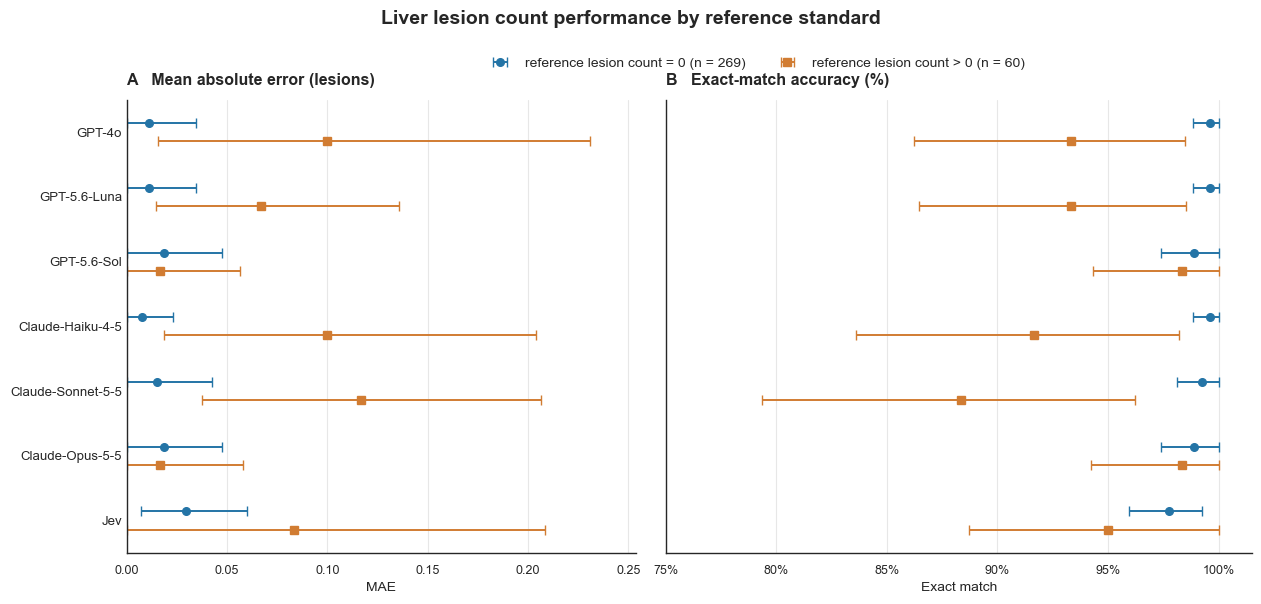

In [14]:
from matplotlib.ticker import PercentFormatter, MultipleLocator

plot_models = list(COUNT_MODEL_ORDER)
if len(plot_models) != 7:
    raise ValueError(f"Expected 7 lesion-count models, got {len(plot_models)}")

strata = [
    ("gt0", "reference lesion count = 0", "#2474A6", "o", -0.14),
    ("gt_positive", "reference lesion count > 0", "#D17C32", "s", +0.14),
]

summary_frames = []
for key, label, _, _, _ in strata:
    if key not in count_tables:
        raise KeyError(f"Run the lesion-count analysis cell first: count_tables[{key!r}] missing")
    frame = count_tables[key].copy()
    if frame["model"].duplicated().any():
        raise ValueError(f"Repeated model entries in {key}")
    missing = set(plot_models) - set(frame["model"])
    if missing:
        raise ValueError(f"Missing models from {key}: {sorted(missing)}")
    frame = frame.set_index("model").loc[plot_models].reset_index()
    frame.insert(0, "reference_group", label)
    frame["exact_match_pct"] = frame["exact_match"] * 100
    frame["exact_match_ci_low_pct"] = frame["exact_match_ci_low"] * 100
    frame["exact_match_ci_high_pct"] = frame["exact_match_ci_high"] * 100
    frame["mae_display"] = frame.apply(
        lambda r: f"{r['mae']:.3f} ({r['mae_ci_low']:.3f}–{r['mae_ci_high']:.3f})"
        if np.isfinite(r["mae"]) and np.isfinite(r["mae_ci_low"]) and np.isfinite(r["mae_ci_high"])
        else "NA", axis=1,
    )
    frame["exact_match_display"] = frame.apply(
        lambda r: f"{r['exact_match_pct']:.1f}% ({r['exact_match_ci_low_pct']:.1f}–{r['exact_match_ci_high_pct']:.1f}%)"
        if np.isfinite(r["exact_match_pct"]) and np.isfinite(r["exact_match_ci_low_pct"]) and np.isfinite(r["exact_match_ci_high_pct"])
        else "NA", axis=1,
    )
    summary_frames.append(frame)

lesion_count_visualization_summary = pd.concat(summary_frames, ignore_index=True)
summary_path = OUTPUT_DIR / "table_lesion_count_mae_exact_match_by_reference_with_95ci.csv"
lesion_count_visualization_summary.to_csv(summary_path, index=False)

fig, axes = plt.subplots(
    1, 2, figsize=(12.5, 5.3), sharey=True,
    gridspec_kw={"width_ratios": [1, 1.15]}, layout="constrained"
)
positions = np.arange(len(plot_models))
metrics = [
    ("mae", "mae_ci_low", "mae_ci_high", "A   Mean absolute error (lesions)"),
    ("exact_match", "exact_match_ci_low", "exact_match_ci_high", "B   Exact-match accuracy (%)"),
]

for panel, (metric, low_col, high_col, title) in zip(axes, metrics):
    for key, label, color, marker, offset in strata:
        data = count_tables[key].set_index("model").loc[plot_models]
        estimate = data[metric].to_numpy(dtype=float)
        lo = data[low_col].to_numpy(dtype=float)
        hi = data[high_col].to_numpy(dtype=float)
        good = np.isfinite(estimate) & np.isfinite(lo) & np.isfinite(hi)
        if good.any():
            panel.errorbar(
                estimate[good], positions[good] + offset,
                xerr=np.vstack([np.maximum(0, estimate[good] - lo[good]),
                                np.maximum(0, hi[good] - estimate[good])]),
                fmt=marker, color=color, ecolor=color,
                markersize=5.5, elinewidth=1.4, capsize=3.5,
                linestyle="none", label=f"{label} (n = {int(data['n_reports'].iloc[0])})"
            )
    panel.set_title(title, fontsize=11.5, fontweight="bold", loc="left", pad=11)
    panel.set_yticks(positions)
    panel.set_yticklabels(plot_models, fontsize=9.5)
    panel.set_ylim(len(plot_models) - 0.5, -0.5)
    panel.grid(axis="x", color="0.86", alpha=0.65, linewidth=0.8)
    panel.set_axisbelow(True)
    panel.spines[["top", "right"]].set_visible(False)
    panel.tick_params(axis="x", labelsize=9)
    panel.tick_params(axis="y", length=0)


mae_upper = max(
    float(np.nanmax(count_tables[k]["mae_ci_high"].to_numpy(dtype=float)))
    for k, *_ in strata
)
axes[0].set_xlim(0, max(0.10, mae_upper * 1.10))
axes[0].set_xlabel("MAE", fontsize=10)


exact_lows = np.concatenate([
    count_tables[k]["exact_match_ci_low"].to_numpy(dtype=float)
    for k, *_ in strata
])
finite_lows = exact_lows[np.isfinite(exact_lows)]
zoom_min = max(0, np.floor((finite_lows.min() - 0.025) * 20) / 20) if len(finite_lows) else 0
axes[1].set_xlim(zoom_min, 1.015)
axes[1].xaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
axes[1].set_xlabel("Exact match", fontsize=10)
axes[1].tick_params(axis="y", labelleft=False)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.60, 1.045),
           ncol=2, frameon=False, fontsize=10)
fig.suptitle("Liver lesion count performance by reference standard", fontsize=14,
             fontweight="bold", y=1.11)

plot_path = OUTPUT_DIR / "figure_lesion_count_mae_exact_match_gt0_vs_positive_95ci.png"
fig.savefig(plot_path, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

## 11. Inter-model agreement: Cohen's kappa plus raw agreement

In [15]:
N_AGREEMENT_REPORTS = len(evaluation_ids)

rng_agreement = np.random.default_rng(RANDOM_SEED)

AGREEMENT_BOOTSTRAP_INDEX = rng_agreement.integers(
    0,
    N_AGREEMENT_REPORTS,
    size=(N_BOOTSTRAP, N_AGREEMENT_REPORTS)
)

In [16]:
# ============================================================
# Cohen's kappa with invalid predictions retained
# ============================================================

def kappa_point_and_boot_codes(a, b, k, boot_idx):
    """
    Cohen's kappa between two models.

    All evaluation reports are retained.

    Valid category codes are assumed to be:
        0, 1, ..., k-1

    Any code outside this range is considered invalid.

    A comparison involving an invalid prediction is treated
    as disagreement.

    Invalid predictions are NOT treated as an additional
    legitimate category when calculating expected agreement.
    """


    valid_a = (a >= 0) & (a < k)
    valid_b = (b >= 0) & (b < k)

    both_valid = valid_a & valid_b


    observed_match = (
        both_valid
        & (a == b)
    )

    po = float(observed_match.mean())


    pa = np.array([
        np.mean(valid_a & (a == cls))
        for cls in range(k)
    ])

    pb = np.array([
        np.mean(valid_b & (b == cls))
        for cls in range(k)
    ])

    pe = float(np.sum(pa * pb))

    point = (
        (po - pe) / (1 - pe)
        if pe < 1
        else np.nan
    )

    a_b = a[boot_idx]
    b_b = b[boot_idx]

    valid_a_b = (a_b >= 0) & (a_b < k)
    valid_b_b = (b_b >= 0) & (b_b < k)

    both_valid_b = valid_a_b & valid_b_b

    observed_match_b = (
        both_valid_b
        & (a_b == b_b)
    )

    po_b = observed_match_b.mean(axis=1)

    # Expected agreement
    pe_b = np.zeros(
        len(boot_idx),
        dtype=float
    )

    for cls in range(k):

        pa_b = (
            valid_a_b
            & (a_b == cls)
        ).mean(axis=1)

        pb_b = (
            valid_b_b
            & (b_b == cls)
        ).mean(axis=1)

        pe_b += pa_b * pb_b

    kappa_b = np.divide(
        po_b - pe_b,
        1 - pe_b,
        out=np.full_like(
            po_b,
            np.nan,
            dtype=float
        ),
        where=(1 - pe_b) != 0,
    )

    return point, kappa_b



HIERARCHICAL_FIELDS = [
    "liver_status",
    "liver_malignancy_status",
    "liver_malignancy_level",
]

BINARY_FIELDS = [
    f for f in CATEGORICAL_FIELDS
    if f not in HIERARCHICAL_FIELDS
]

assert len(BINARY_FIELDS) == 8
assert len(HIERARCHICAL_FIELDS) == 3

MODEL_PAIRS = list(combinations(MODEL_ORDER, 2))

kappa_rows = []
raw_rows = []

# Store bootstrap distributions for group-level CIs
kappa_boot_by_field = {
    field: [] for field in CATEGORICAL_FIELDS
}

for field in CATEGORICAL_FIELDS:

    info = ENCODED[field]

    for model_a, model_b in MODEL_PAIRS:

        a = info["pred"][model_a]
        b = info["pred"][model_b]

        assert len(a) == N_AGREEMENT_REPORTS
        assert len(b) == N_AGREEMENT_REPORTS


        valid_a = (a >= 0) & (a < info["k"])
        valid_b = (b >= 0) & (b < info["k"])

        both_valid = valid_a & valid_b

        # Invalid predictions count as disagreement
        matches = both_valid & (a == b)

        raw = float(matches.mean())

        n_invalid_a = int((~valid_a).sum())
        n_invalid_b = int((~valid_b).sum())
        n_any_invalid = int((~both_valid).sum())

        kappa, kappa_boot = kappa_point_and_boot_codes(
            a,
            b,
            info["k"],
            boot_idx=AGREEMENT_BOOTSTRAP_INDEX,
        )

        lo, hi = percentile_ci(kappa_boot)

        # Save bootstrap distribution for summary rows
        kappa_boot_by_field[field].append(kappa_boot)

        kappa_rows.append({
            "field": field,
            "model_a": model_a,
            "model_b": model_b,
            "n_reports": len(a),
            "n_any_invalid": n_any_invalid,
            "kappa": kappa,
            "kappa_ci_low": lo,
            "kappa_ci_high": hi,
            "valid_bootstrap_replicates": int(
                np.isfinite(kappa_boot).sum()
            ),
        })

        raw_rows.append({
            "field": field,
            "model_a": model_a,
            "model_b": model_b,
            "n_reports": len(a),
            "n_invalid_model_a": n_invalid_a,
            "n_invalid_model_b": n_invalid_b,
            "n_any_invalid": n_any_invalid,
            "raw_agreement": raw,
        })



intermodel_kappa = pd.DataFrame(kappa_rows)
intermodel_raw = pd.DataFrame(raw_rows)


AGREEMENT_GROUPS = [
    ("Mean (8 binary fields)", BINARY_FIELDS),
    ("Mean (3 hierarchical fields)", HIERARCHICAL_FIELDS),
]

kappa_summary_rows = []
raw_summary_rows = []

for group_label, fields in AGREEMENT_GROUPS:

    # Select all model-pair comparisons for these fields
    kappa_subset = intermodel_kappa[
        intermodel_kappa["field"].isin(fields)
    ]

    raw_subset = intermodel_raw[
        intermodel_raw["field"].isin(fields)
    ]

    expected_comparisons = len(fields) * len(MODEL_PAIRS)

    assert len(kappa_subset) == expected_comparisons
    assert len(raw_subset) == expected_comparisons


    mean_kappa = float(
        kappa_subset["kappa"].mean(skipna=False)
    )

    boot_matrix = np.vstack([
        boot
        for field in fields
        for boot in kappa_boot_by_field[field]
    ])


    valid_boot = np.isfinite(boot_matrix).all(axis=0)

    mean_kappa_boot = np.full(
        boot_matrix.shape[1],
        np.nan,
        dtype=float,
    )

    mean_kappa_boot[valid_boot] = (
        boot_matrix[:, valid_boot].mean(axis=0)
    )

    kappa_lo, kappa_hi = percentile_ci(
        mean_kappa_boot
    )

    kappa_summary_rows.append({
        "field": group_label,
        "model_a": "All model pairs",
        "model_b": "",
        "n_reports": N_AGREEMENT_REPORTS,
        "n_any_invalid": np.nan,
        "kappa": mean_kappa,
        "kappa_ci_low": kappa_lo,
        "kappa_ci_high": kappa_hi,
        "valid_bootstrap_replicates": int(
            valid_boot.sum()
        ),
    })


    mean_raw = float(
        raw_subset["raw_agreement"].mean()
    )

    raw_summary_rows.append({
        "field": group_label,
        "model_a": "All model pairs",
        "model_b": "",
        "n_reports": N_AGREEMENT_REPORTS,
        "n_invalid_model_a": np.nan,
        "n_invalid_model_b": np.nan,
        "n_any_invalid": np.nan,
        "raw_agreement": mean_raw,
    })



intermodel_kappa = pd.concat(
    [
        intermodel_kappa,
        pd.DataFrame(kappa_summary_rows),
    ],
    ignore_index=True,
)

intermodel_raw = pd.concat(
    [
        intermodel_raw,
        pd.DataFrame(raw_summary_rows),
    ],
    ignore_index=True,
)



intermodel_kappa.to_csv(
    OUTPUT_DIR / "supplement_intermodel_cohen_kappa.csv",
    index=False,
)

intermodel_raw.to_csv(
    OUTPUT_DIR / "supplement_intermodel_raw_agreement.csv",
    index=False,
)



In [17]:

# ============================================================
# TABLE 4 — INTER-MODEL AGREEMENT AND REFERENCE CONCORDANCE
# 11 categorical fields + 3 summary rows
# ============================================================

import numpy as np
import pandas as pd
from itertools import combinations
from IPython.display import display


INCLUDE_GPT4O = True
INCLUDE_CLAUDE_HAIKU = True
INCLUDE_JEV = True

BASE_MODELS = [
    "GPT-5.6-Luna",
    "GPT-5.6-Sol",
    "Claude-Sonnet-5-5",
    "Claude-Opus-5-5",
]
FIELD_DISPLAY = {
    "further_exam_required": "Further examination required",
    "hepatomegaly": "Hepatomegaly",
    "intrahepatic_duct_dilation": "Intrahepatic duct dilation",
    "liver_calcification": "Calcification",
    "liver_cirrhosis": "Cirrhosis",
    "liver_malignancy_level": "Malignancy level",
    "liver_malignancy_status": "Malignancy status",
    "liver_status": "Liver status",
    "liver_steatosis": "Steatosis",
    "liver_vague_multiple_present": "Vague multiple lesions",
    "liver_vascular_disease": "Vascular disease",
}

CLASS_DISPLAY = {
    "y": "Y",
    "n": "N",
    "normal": "Normal",
    "abnormal": "Abnormal",
    "not_mentioned": "Not mentioned",
    "malignant": "Malignant",
    "not_malignant": "Not malignant",
    "primary": "Primary",
    "secondary": "Secondary",
    INVALID_PREDICTION: "Invalid prediction",
}


requested_models = BASE_MODELS.copy()

if INCLUDE_GPT4O:
    requested_models.append("GPT-4o")

if INCLUDE_CLAUDE_HAIKU:
    requested_models.append("Claude-Haiku-4-5")

if INCLUDE_JEV:
    requested_models.append("Jev")

missing_models = set(requested_models) - set(CONSENSUS_MODEL_ORDER)

if missing_models:
    raise ValueError(f"Models missing from MODEL_ORDER: {missing_models}")

SELECTED_MODELS = [
    m for m in CONSENSUS_MODEL_ORDER if m in requested_models
]

N_MODELS = len(SELECTED_MODELS)
MODEL_PAIRS = list(combinations(SELECTED_MODELS, 2))

print(f"Models included ({N_MODELS}):")
for model in SELECTED_MODELS:
    print(f"  - {model}")

print(f"Number of model pairs: {len(MODEL_PAIRS)}")



if "REFERENCE_BY_FIELD" not in globals():
    if "gt_cat" in globals():
        REFERENCE_BY_FIELD = gt_cat
    else:
        raise RuntimeError(
            "Reference labels are required. Define "
            "REFERENCE_BY_FIELD = <your ground-truth mapping>."
        )


HIERARCHICAL_FIELDS = [
    "liver_status",
    "liver_malignancy_status",
    "liver_malignancy_level",
]

BINARY_FIELDS = [
    f for f in CATEGORICAL_FIELDS
    if f not in HIERARCHICAL_FIELDS
]



POSITIVE_CLASS = {
    "liver_status": "abnormal",
    "liver_malignancy_status": "malignant",
    "liver_malignancy_level": None,
}

for field in BINARY_FIELDS:
    POSITIVE_CLASS[field] = "y"

CLASS_LABELS = {
    "y": "Yes",
    "abnormal": "Abnormal",
    "malignant": "Malignant",
}

VALID_CLASSES = {
    "liver_status": {
        "normal", "abnormal", "not_mentioned"
    },
    "liver_malignancy_status": {
        "malignant", "not_malignant", "not_mentioned"
    },
    "liver_malignancy_level": {
        "primary", "secondary", "not_mentioned"
    },
}

for field in BINARY_FIELDS:
    VALID_CLASSES[field] = {"y", "n"}



def normalize_label(value):
    if pd.isna(value):
        return None

    return (
        str(value)
        .strip()
        .lower()
        .replace(" ", "_")
        .replace("-", "_")
    )


def format_count(n, total):
    if total == 0:
        return "—"

    return f"{n:,} ({100 * n / total:.1f})"


def format_pct(value):
    return f"{100 * value:.1f}" if np.isfinite(value) else "—"


def format_kappa(value):
    return f"{value:.3f}" if np.isfinite(value) else "—"


def field_label(field):
    return FIELD_DISPLAY.get(
        field,
        field.replace("_", " ").title()
    )


def pairwise_metrics(a, b, valid_classes):
    """
    Calculate raw pairwise agreement and Cohen's kappa.

    Invalid predictions always count as disagreements,
    even when both models produce the same invalid output.

    Invalid outputs do not contribute to expected agreement.
    """

    valid_a = np.isin(a, list(valid_classes))
    valid_b = np.isin(b, list(valid_classes))

    matches = valid_a & valid_b & (a == b)

    po = float(matches.mean())

    pe = sum(
        float(np.mean(a == cls) * np.mean(b == cls))
        for cls in valid_classes
    )

    kappa = (
        (po - pe) / (1 - pe)
        if not np.isclose(pe, 1.0)
        else np.nan
    )

    return matches, po, kappa



field_results = []

for field in CATEGORICAL_FIELDS:

    allowed = VALID_CLASSES[field]

    # Ground-truth labels
    gt = np.array([
        normalize_label(x)
        for x in REFERENCE_BY_FIELD[field]
    ], dtype=object)

    n_reports = len(gt)

    invalid_gt = set(gt) - allowed
    if invalid_gt:
        raise ValueError(
            f"Unexpected reference labels for {field}: {invalid_gt}"
        )

    # Model predictions (same report order as reference)
    predictions = {}

    for model in SELECTED_MODELS:

        predictions[model] = np.array([
            normalize_label(x)
            for x in pred_cat[model][field]
        ], dtype=object)

        assert len(predictions[model]) == n_reports, (
            f"Report-count mismatch: {model}, {field}"
        )


    pred_matrix = np.vstack([
        predictions[m] for m in SELECTED_MODELS
    ])

    all_valid = np.isin(
        pred_matrix, list(allowed)
    ).all(axis=0)

    all_same = (
        pred_matrix == pred_matrix[0]
    ).all(axis=0)

    unanimous = all_valid & all_same

    unanimous_correct = (
        unanimous & (pred_matrix[0] == gt)
    )

    n_unanimous = int(unanimous.sum())
    n_unanimous_correct = int(unanimous_correct.sum())
    n_nonunanimous = n_reports - n_unanimous



    pairwise_raw = []
    pairwise_kappa = []

    positive_class = POSITIVE_CLASS[field]

    positive_mask = (
        gt == positive_class
        if positive_class is not None
        else np.zeros(n_reports, dtype=bool)
    )

    n_positive = int(positive_mask.sum())

    positive_pairwise_raw = []

    for model_a, model_b in MODEL_PAIRS:

        a = predictions[model_a]
        b = predictions[model_b]

        matches, raw, kappa = pairwise_metrics(
            a, b, allowed
        )

        pairwise_raw.append(raw)
        pairwise_kappa.append(kappa)

        if n_positive > 0:
            positive_pairwise_raw.append(
                float(matches[positive_mask].mean())
            )

    mean_raw = float(np.mean(pairwise_raw))
    mean_kappa = float(np.mean(pairwise_kappa))


    if positive_class is not None and n_positive > 0:

        n_positive_unanimous = int(
            (unanimous & positive_mask).sum()
        )

        n_positive_correct = int(
            (unanimous_correct & positive_mask).sum()
        )

        mean_positive_raw = float(
            np.mean(positive_pairwise_raw)
        )

        positive_label = (
            f"{CLASS_LABELS.get(positive_class, positive_class)}"
            f": {n_positive}"
        )

    else:
        n_positive_unanimous = None
        n_positive_correct = None
        mean_positive_raw = np.nan
        positive_label = "—"

    field_results.append({
        "field": field,
        "n_reports": n_reports,
        "nonunanimous_n": n_nonunanimous,
        "unanimous_n": n_unanimous,
        "unanimous_correct_n": n_unanimous_correct,
        "pairwise_raw": mean_raw,
        "kappa": mean_kappa,
        "pairwise_raw_values": pairwise_raw,
        "kappa_values": pairwise_kappa,
        "positive_class": positive_label,
        "n_positive": n_positive,
        "positive_pairwise": mean_positive_raw,
        "positive_unanimous_n": n_positive_unanimous,
        "positive_correct_n": n_positive_correct,
    })



SUMMARY_GROUPS = [
    ("8 binary fields", BINARY_FIELDS),
    ("3 hierarchical fields", HIERARCHICAL_FIELDS),
    ("All 11 fields", CATEGORICAL_FIELDS),
]

summary_results = []

for label, fields in SUMMARY_GROUPS:

    subset = [
        r for r in field_results
        if r["field"] in fields
    ]

    total_reports = sum(r["n_reports"] for r in subset)

    total_nonunanimous = sum(
        r["nonunanimous_n"] for r in subset
    )

    total_unanimous = sum(
        r["unanimous_n"] for r in subset
    )

    total_unanimous_correct = sum(
        r["unanimous_correct_n"] for r in subset
    )

    # Average across all fields and selected model pairs
    raw_values = [
        value
        for r in subset
        for value in r["pairwise_raw_values"]
    ]

    kappa_values = [
        value
        for r in subset
        for value in r["kappa_values"]
    ]

    summary_results.append({
        "field": label,
        "n_reports": total_reports,
        "nonunanimous_n": total_nonunanimous,
        "unanimous_n": total_unanimous,
        "unanimous_correct_n": total_unanimous_correct,
        "pairwise_raw": float(np.mean(raw_values)),
        "kappa": float(np.mean(kappa_values)),
        "positive_class": "—",
        "n_positive": 0,
        "positive_pairwise": np.nan,
        "positive_unanimous_n": None,
        "positive_correct_n": None,
    })


field_results = sorted(
    field_results,
    key=lambda r: r["nonunanimous_n"],
    reverse=True,
)

all_results = field_results + summary_results

rows = []

for r in all_results:

    n = r["n_reports"]
    n_pos = r["n_positive"]

    rows.append({
        "Field": field_label(r["field"])
            if r in field_results else r["field"],

        "Non-unanimous, n (%)": format_count(
            r["nonunanimous_n"], n
        ),

        "Unanimous, n (%)": format_count(
            r["unanimous_n"], n
        ),

        # Denominator is unanimous decisions, NOT all reports.
        # Includes every reference class (Y/N, normal/abnormal/etc.).
        "Unanimous matching reference, n (%)": format_count(
            r["unanimous_correct_n"], r["unanimous_n"]
        ),

        "Pairwise agreement, %": format_pct(
            r["pairwise_raw"]
        ),

        "Mean κ": format_kappa(r["kappa"]),

        "Reference-positive class, n": r["positive_class"],

        "Pairwise agreement in positive class, %":
            format_pct(r["positive_pairwise"]),

        f"All {N_MODELS} agree in positive class, n (%)":
            (
                format_count(r["positive_unanimous_n"], n_pos)
                if r["positive_unanimous_n"] is not None
                else "—"
            ),

        f"All {N_MODELS} correct in positive class, n (%)":
            (
                format_count(r["positive_correct_n"], n_pos)
                if r["positive_correct_n"] is not None
                else "—"
            ),
    })


table4 = pd.DataFrame(rows)

output_path = (
    OUTPUT_DIR /
    f"table4_intermodel_agreement_{N_MODELS}_models.csv"
)

table4.to_csv(output_path, index=False)


Models included (7):
  - GPT-4o
  - GPT-5.6-Luna
  - GPT-5.6-Sol
  - Claude-Haiku-4-5
  - Claude-Sonnet-5-5
  - Claude-Opus-5-5
  - Jev
Number of model pairs: 21


In [18]:

import numpy as np
import pandas as pd

# Numeric unanimity now includes Jev because COUNT_MODEL_ORDER includes all seven models.
# A missing numeric prediction prevents unanimity, rather than becoming zero.
gt = gt_count.to_numpy(dtype=float)
preds = np.column_stack([
    pred_count[m].to_numpy(dtype=float)
    for m in COUNT_MODEL_ORDER
])

valid = np.isfinite(preds).all(axis=1)
unanimous = valid & (preds == preds[:, [0]]).all(axis=1)
correct = unanimous & (preds[:, 0] == gt)

for name, mask in {
    "Reference = 0": np.isfinite(gt) & (gt == 0),
    "Reference > 0": np.isfinite(gt) & (gt > 0)
}.items():
    print(
        name,
        "Unanimity:", f"{100 * unanimous[mask].mean():.3f}%",
        "Unanimously correct:", f"{100 * correct[mask].mean():.3f}%"
    )


Reference = 0 Unanimity: 97.026% Unanimously correct: 97.026%
Reference > 0 Unanimity: 75.000% Unanimously correct: 75.000%


Total report-field decisions: 3619
Unique modal prediction errors: 41
Ties/unresolved: 1


,Threshold,Accepted labels,Coverage (%),Correct accepted,Incorrect accepted,Accepted accuracy (%),Errors captured,Errors missed,Error capture (%),Labels reviewed,Reports reviewed,Reports reviewed (%)
0,≥6/6,3527,97.46,3514,13,99.63,28,13,68.29,92,61,18.54
1,≥5/6,3568,98.59,3546,22,99.38,19,22,46.34,51,35,10.64
2,≥4/6,3618,99.97,3577,41,98.87,0,41,0.00,1,1,0.30
3,≥3/6,3618,99.97,3577,41,98.87,0,41,0.00,1,1,0.30


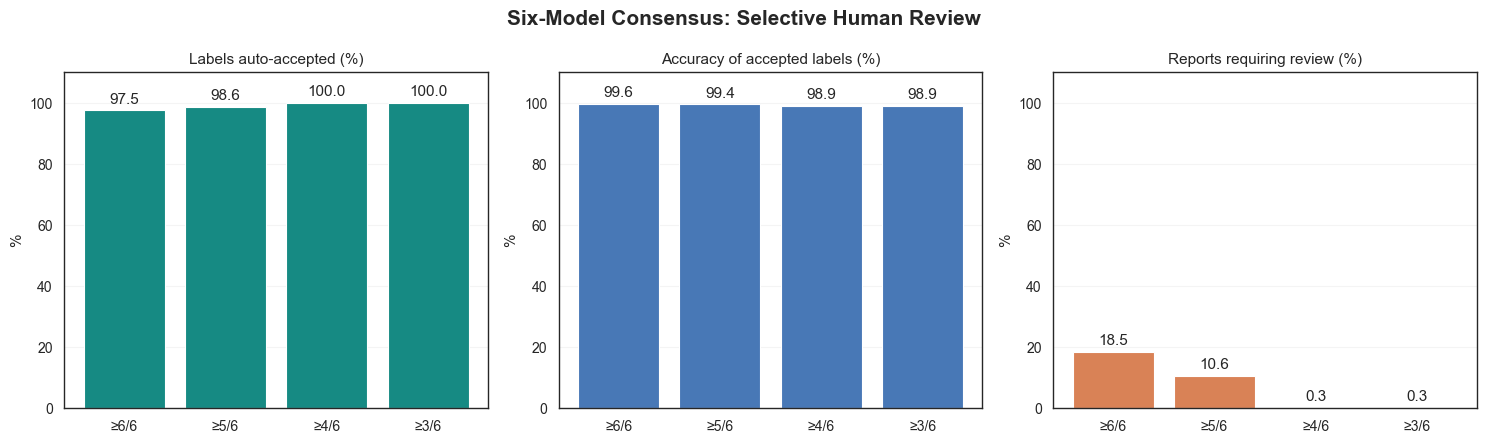

In [19]:

# ============================================================
# SIX-MODEL CONSENSUS: SELECTIVE HUMAN REVIEW
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Rebuild consensus for every report-field decision

rows = []

for field in CATEGORICAL_FIELDS:
    for rid in evaluation_ids:

        predictions = [
            pred_cat[model].loc[rid, field]
            for model in CONSENSUS_MODEL_ORDER
        ]

        valid = [
            p for p in predictions
            if p != INVALID_PREDICTION and pd.notna(p)
        ]

        counts = pd.Series(valid).value_counts()

        # A unique modal label is required for auto-acceptance
        unique_mode = (
            len(counts) > 0
            and (len(counts) == 1 or counts.iloc[0] > counts.iloc[1])
        )

        modal_label = counts.index[0] if unique_mode else None
        max_votes = int(counts.iloc[0]) if unique_mode else 0

        # Any invalid model output forces human review
        eligible = unique_mode and len(valid) == len(CONSENSUS_MODEL_ORDER)

        rows.append({
            "report_id": rid,
            "field": field,
            "reference": gt_cat.loc[rid, field],
            "modal_label": modal_label,
            "max_votes": max_votes,
            "eligible": eligible,
            "modal_error": (
                modal_label != gt_cat.loc[rid, field]
                if unique_mode else False
            )
        })

triage_df = pd.DataFrame(rows)

# 2. Evaluate the four acceptance thresholds

results = []

# Modal error is defined only for decisions with a unique mode.
assessable = triage_df["modal_label"].notna()
total_errors = int(triage_df.loc[assessable, "modal_error"].sum())

for threshold in [6, 5, 4, 3]:

    accepted = (
        triage_df["eligible"]
        & (triage_df["max_votes"] >= threshold)
    )
    reviewed = ~accepted

    correct = int((accepted & ~triage_df["modal_error"]).sum())
    missed_errors = int(
        (accepted & triage_df["modal_error"]).sum()
    )
    captured_errors = int(
        (reviewed & triage_df["modal_error"]).sum()
    )

    # A report requires review if ANY field is flagged
    reports_reviewed = int(
        triage_df.loc[reviewed, "report_id"].nunique()
    )

    n_accepted = int(accepted.sum())
    n_reviewed = int(reviewed.sum())

    results.append({
        "Threshold": f"≥{threshold}/6",
        "Accepted labels": n_accepted,
        "Coverage (%)": 100 * n_accepted / len(triage_df),
        "Correct accepted": correct,
        "Incorrect accepted": missed_errors,
        "Accepted accuracy (%)":
            100 * correct / n_accepted if n_accepted else np.nan,
        "Errors captured": captured_errors,
        "Errors missed": missed_errors,
        "Error capture (%)":
            100 * captured_errors / total_errors
            if total_errors else np.nan,
        "Labels reviewed": n_reviewed,
        "Reports reviewed": reports_reviewed,
        "Reports reviewed (%)":
            100 * reports_reviewed / len(evaluation_ids)
    })

triage_results = pd.DataFrame(results)

print("Total report-field decisions:", len(triage_df))
print("Unique modal prediction errors:", total_errors)
print("Ties/unresolved:", int((~assessable).sum()))

display(triage_results.round(2))

# 3. Visualize the trade-off

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

metrics = [
    ("Coverage (%)", "Labels auto-accepted (%)", "#168A83"),
    ("Accepted accuracy (%)", "Accuracy of accepted labels (%)", "#4878B6"),
    ("Reports reviewed (%)", "Reports requiring review (%)", "#D98256")
]

for ax, (metric, title, color) in zip(axes, metrics):
    bars = ax.bar(
        triage_results["Threshold"],
        triage_results[metric],
        color=color
    )
    ax.bar_label(bars, fmt="%.1f", padding=3)
    ax.set_title(title)
    ax.set_ylabel("%")
    ax.set_ylim(0, 110)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

fig.suptitle(
    "Six-Model Consensus: Selective Human Review",
    fontsize=15,
    fontweight="bold"
)
fig.tight_layout()
plt.show()

# 4. Save results

triage_results.to_csv(
    OUTPUT_DIR / "six_model_triage_summary.csv",
    index=False
)

triage_df.to_csv(
    OUTPUT_DIR / "six_model_triage_decisions.csv",
    index=False
)


## 12. Inter-radiologist agreement


In [22]:
human_agreement_rows = []
if len(RADIOLOGIST_PATHS) == 0:
    print("Human agreement skipped: RADIOLOGIST_PATHS is empty.")
elif len(RADIOLOGIST_PATHS) != 2:
    raise ValueError("RADIOLOGIST_PATHS must contain exactly two independently annotating radiologists.")
else:
    human = {}
    for radiologist, path in RADIOLOGIST_PATHS.items():
        frame = read_table(path)
        require_fields(frame, radiologist)
        human[radiologist] = frame
    radiologist_a, radiologist_b = list(human)
    common_ids = human[radiologist_a].index.intersection(human[radiologist_b].index).tolist()

    human_boot_idx = np.random.default_rng(RANDOM_SEED + 900).integers(
        0, len(common_ids), size=(N_BOOTSTRAP, len(common_ids)), dtype=np.int32
    )

    for field in CATEGORICAL_FIELDS:
        a_s = human[radiologist_a].loc[common_ids, field].map(normalize_value)
        b_s = human[radiologist_b].loc[common_ids, field].map(normalize_value)
        if (a_s == "").any() or (b_s == "").any():
            raise ValueError(f"Missing human label in {field}; do not silently drop radiologist disagreements.")
        labels = sorted(set(a_s) | set(b_s))
        mapping = {label: i for i, label in enumerate(labels)}
        a = a_s.map(mapping).to_numpy(dtype=np.int16)
        b = b_s.map(mapping).to_numpy(dtype=np.int16)
        kappa, kappa_boot = kappa_point_and_boot_codes(a, b, len(labels), human_boot_idx)
        lo, hi = percentile_ci(kappa_boot)
        human_agreement_rows.append({
            "field": field,
            "metric": "categorical",
            "n": len(common_ids),
            "kappa": kappa,
            "kappa_ci_low": lo,
            "kappa_ci_high": hi,
            "raw_agreement": float(np.mean(a == b)),
            "mae": np.nan,
            "mae_ci_low": np.nan,
            "mae_ci_high": np.nan,
            "exact_match": np.nan,
            "exact_match_ci_low": np.nan,
            "exact_match_ci_high": np.nan,
        })

    a_count = human[radiologist_a].loc[common_ids, NUMERIC_FIELD].map(parse_count).to_numpy(dtype=float)
    b_count = human[radiologist_b].loc[common_ids, NUMERIC_FIELD].map(parse_count).to_numpy(dtype=float)
    both_numeric = np.isfinite(a_count) & np.isfinite(b_count)
    if both_numeric.any():
        abs_err = np.full(len(common_ids), np.nan)
        abs_err[both_numeric] = np.abs(a_count[both_numeric] - b_count[both_numeric])
        exact_vec = np.zeros(len(common_ids), dtype=float)
        exact_vec[both_numeric] = (a_count[both_numeric] == b_count[both_numeric]).astype(float)
        mae = float(np.nanmean(abs_err))
        exact = float(exact_vec[both_numeric].mean())
        abs_b = abs_err[human_boot_idx]
        finite_b = np.isfinite(abs_b)
        mae_boot = np.divide(
            np.nansum(abs_b, axis=1), finite_b.sum(axis=1),
            out=np.full(N_BOOTSTRAP, np.nan), where=finite_b.sum(axis=1) > 0
        )
        both_b = both_numeric[human_boot_idx]
        exact_b = exact_vec[human_boot_idx]
        exact_boot = np.divide(
            (exact_b * both_b).sum(axis=1), both_b.sum(axis=1),
            out=np.full(N_BOOTSTRAP, np.nan), where=both_b.sum(axis=1) > 0
        )
        mae_lo, mae_hi = percentile_ci(mae_boot)
        ex_lo, ex_hi = percentile_ci(exact_boot)
    else:
        mae = exact = mae_lo = mae_hi = ex_lo = ex_hi = np.nan

    human_agreement_rows.append({
        "field": NUMERIC_FIELD,
        "metric": "numeric",
        "n": int(both_numeric.sum()),
        "kappa": np.nan,
        "kappa_ci_low": np.nan,
        "kappa_ci_high": np.nan,
        "raw_agreement": np.nan,
        "mae": mae,
        "mae_ci_low": mae_lo,
        "mae_ci_high": mae_hi,
        "exact_match": exact,
        "exact_match_ci_low": ex_lo,
        "exact_match_ci_high": ex_hi,
    })

    human_agreement = pd.DataFrame(human_agreement_rows)
    human_agreement.to_csv(OUTPUT_DIR / "table6_human_interradiologist_agreement.csv", index=False)
    display(human_agreement)

,field,metric,n,kappa,kappa_ci_low,kappa_ci_high,raw_agreement,mae,mae_ci_low,mae_ci_high,exact_match,exact_match_ci_low,exact_match_ci_high
0,liver_status,categorical,329,0.963669,0.934518,0.989460,0.978723,NaN,NaN,NaN,NaN,NaN,NaN
1,liver_malignancy_status,categorical,329,0.927740,0.875395,0.972169,0.975684,NaN,NaN,NaN,NaN,NaN,NaN
2,liver_malignancy_level,categorical,329,1.000000,1.000000,1.000000,1.000000,NaN,NaN,NaN,NaN,NaN,NaN
3,liver_steatosis,categorical,329,0.974729,0.932568,1.000000,0.993921,NaN,NaN,NaN,NaN,NaN,NaN
4,liver_cirrhosis,categorical,329,0.663599,-0.004069,1.000000,0.993921,NaN,NaN,NaN,NaN,NaN,NaN
5,hepatomegaly,categorical,329,0.946772,0.854059,1.000000,0.993921,NaN,NaN,NaN,NaN,NaN,NaN
6,liver_vascular_disease,categorical,329,0.854102,0.539345,1.000000,0.993921,NaN,NaN,NaN,NaN,NaN,NaN
7,liver_calcification,categorical,329,1.000000,1.000000,1.000000,1.000000,NaN,NaN,NaN,NaN,NaN,NaN
8,intrahepatic_duct_dilation,categorical,329,0.869950,0.737135,0.969825,0.984802,NaN,NaN,NaN,NaN,NaN,NaN
9,further_exam_required,categorical,329,1.000000,1.000000,1.000000,1.000000,NaN,NaN,NaN,NaN,NaN,NaN


## 13. Figures

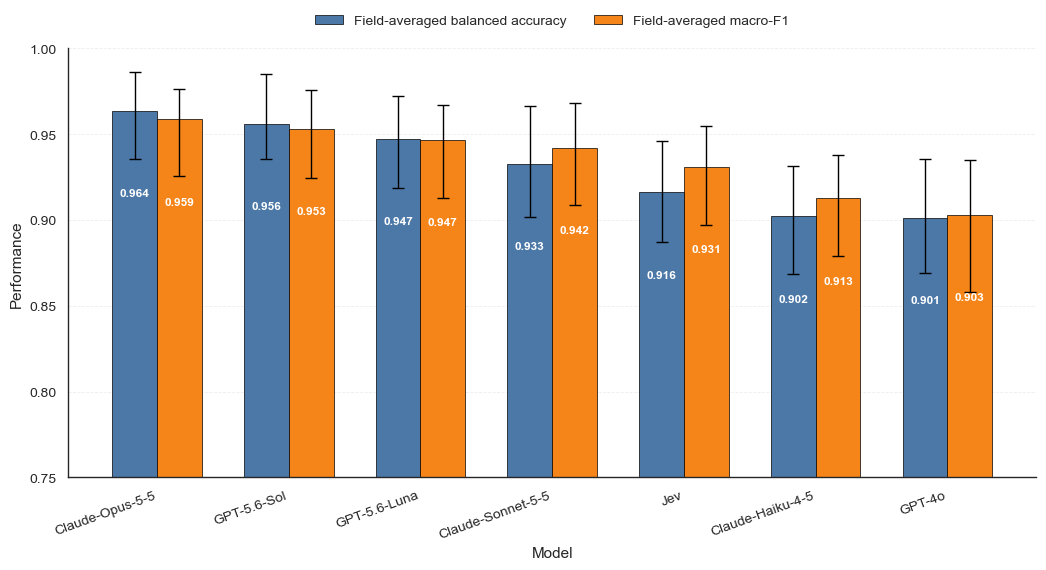

In [23]:
import numpy as np
import matplotlib.pyplot as plt

# Keep ordering from overall_performance
plot_df = overall_performance.copy()

models = plot_df["model"].tolist()
x = np.arange(len(models))
width = 0.34

# Point estimates
ba = plot_df["field_averaged_balanced_accuracy"].to_numpy()
f1 = plot_df["field_averaged_macro_f1"].to_numpy()

# Asymmetric 95% confidence intervals
ba_err = np.vstack([
    ba - plot_df["ba_ci_low"].to_numpy(),
    plot_df["ba_ci_high"].to_numpy() - ba
])

f1_err = np.vstack([
    f1 - plot_df["f1_ci_low"].to_numpy(),
    plot_df["f1_ci_high"].to_numpy() - f1
])

ba_color = "#4C78A8"
f1_color = "#F58518"

fig, ax = plt.subplots(figsize=(11, 6.5))

bars_ba = ax.bar(
    x - width / 2,
    ba,
    width,
    yerr=ba_err,
    capsize=4,
    color=ba_color,
    edgecolor="black",
    linewidth=0.5,
    error_kw={
        "ecolor": "black",
        "elinewidth": 1,
        "capthick": 1
    },
    label="Field-averaged balanced accuracy"
)

bars_f1 = ax.bar(
    x + width / 2,
    f1,
    width,
    yerr=f1_err,
    capsize=4,
    color=f1_color,
    edgecolor="black",
    linewidth=0.5,
    error_kw={
        "ecolor": "black",
        "elinewidth": 1,
        "capthick": 1
    },
    label="Field-averaged macro-F1"
)


ax.set_ylabel("Performance", fontsize=11)
ax.set_xlabel("Model", fontsize=11)

ax.set_xticks(x)
ax.set_xticklabels(
    models,
    rotation=20,
    ha="right",
    fontsize=10
)


ax.set_ylim(0.75, 1.00)

ax.tick_params(axis="y", labelsize=10)

ax.yaxis.grid(
    True,
    linestyle="--",
    linewidth=0.6,
    alpha=0.35
)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(
    loc="lower center",
    bbox_to_anchor=(0.5, 1.02),
    ncol=2,
    frameon=False,
    fontsize=10
)


for bars in [bars_ba, bars_f1]:
    for bar in bars:
        value = bar.get_height()

        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value - 0.045,
            f"{value:.3f}",
            ha="center",
            va="top",
            fontsize=8.5,
            color="white",
            fontweight="bold"
        )

fig.subplots_adjust(
    top=0.86,
    bottom=0.20,
    left=0.10,
    right=0.98
)


plt.savefig(
    OUTPUT_DIR / "figure_field_averaged_model_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

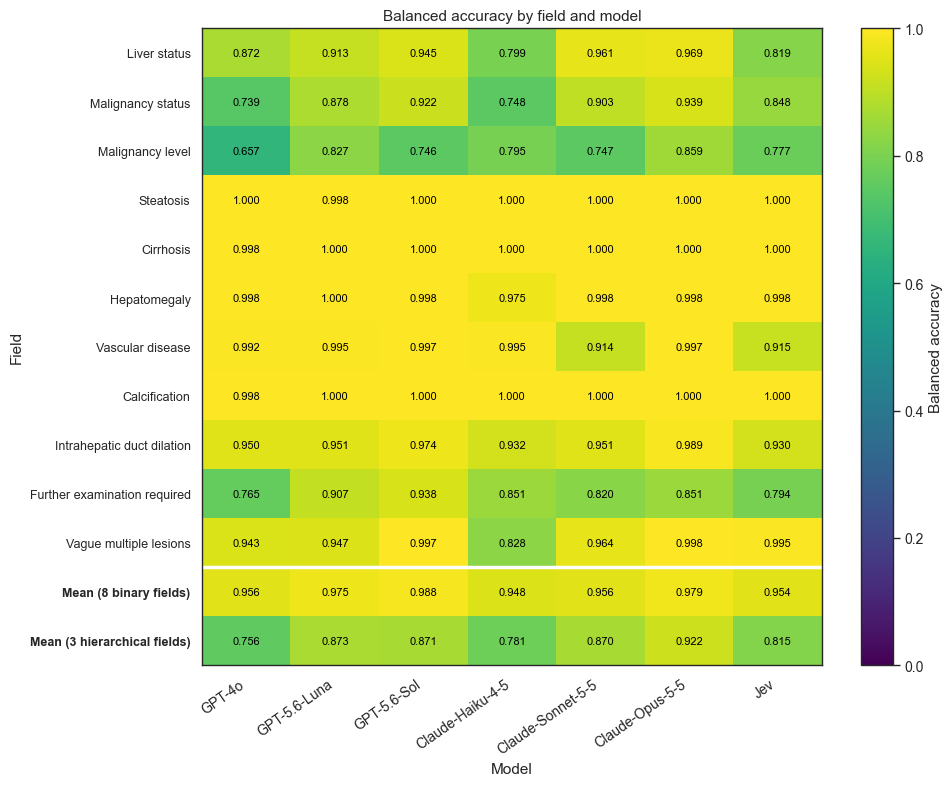

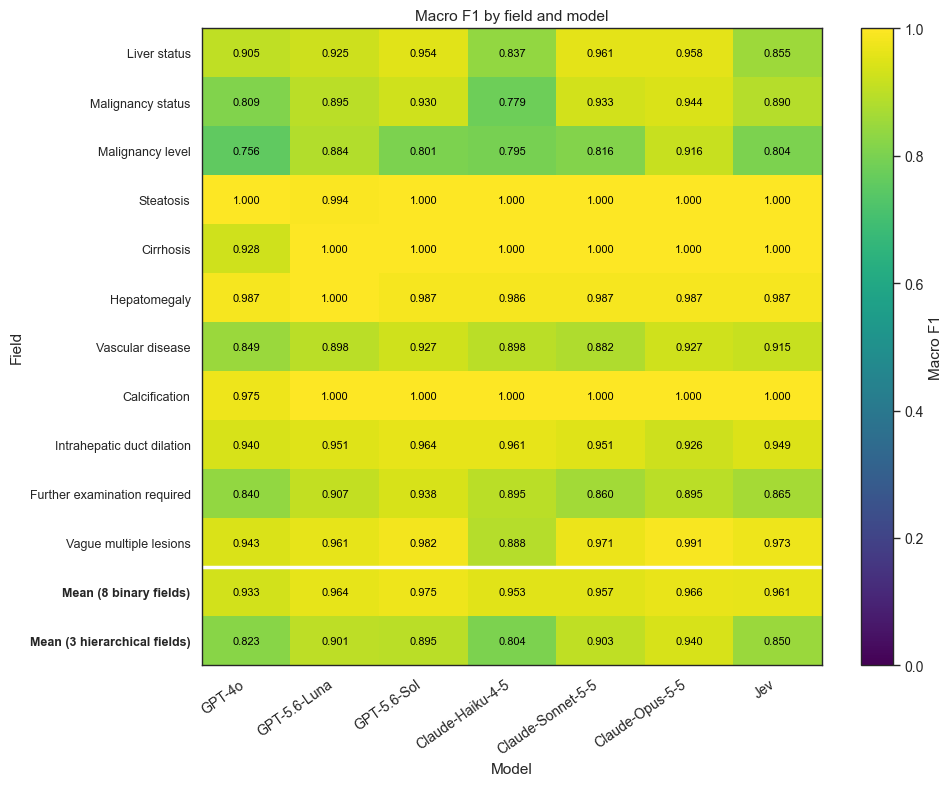


PER-CLASS F1 SCORES


model,GPT-4o,GPT-5.6-Luna,GPT-5.6-Sol,Claude-Haiku-4-5,Claude-Sonnet-5-5,Claude-Opus-5-5,Jev
field_class,,,,,,,
Liver status | Abnormal (n=136),0.974,0.971,0.975,0.934,0.971,0.975,0.967
Liver status | Normal (n=158),0.948,0.956,0.962,0.910,0.968,0.968,0.931
Liver status | Not mentioned (n=35),0.793,0.848,0.925,0.667,0.943,0.932,0.667
Malignancy status | Malignant (n=14),0.727,0.846,0.889,0.786,0.880,0.923,0.963
Malignancy status | Not malignant (n=260),0.957,0.975,0.981,0.939,0.990,0.986,0.959
Malignancy status | Not mentioned (n=55),0.742,0.865,0.919,0.612,0.927,0.923,0.747
Malignancy level | Not mentioned (n=315),0.991,0.994,0.994,0.990,0.995,0.997,0.997
Malignancy level | Primary (n=3),0.500,0.800,0.500,0.667,0.500,0.800,0.500
Malignancy level | Secondary (n=11),0.778,0.857,0.909,0.727,0.952,0.952,0.917


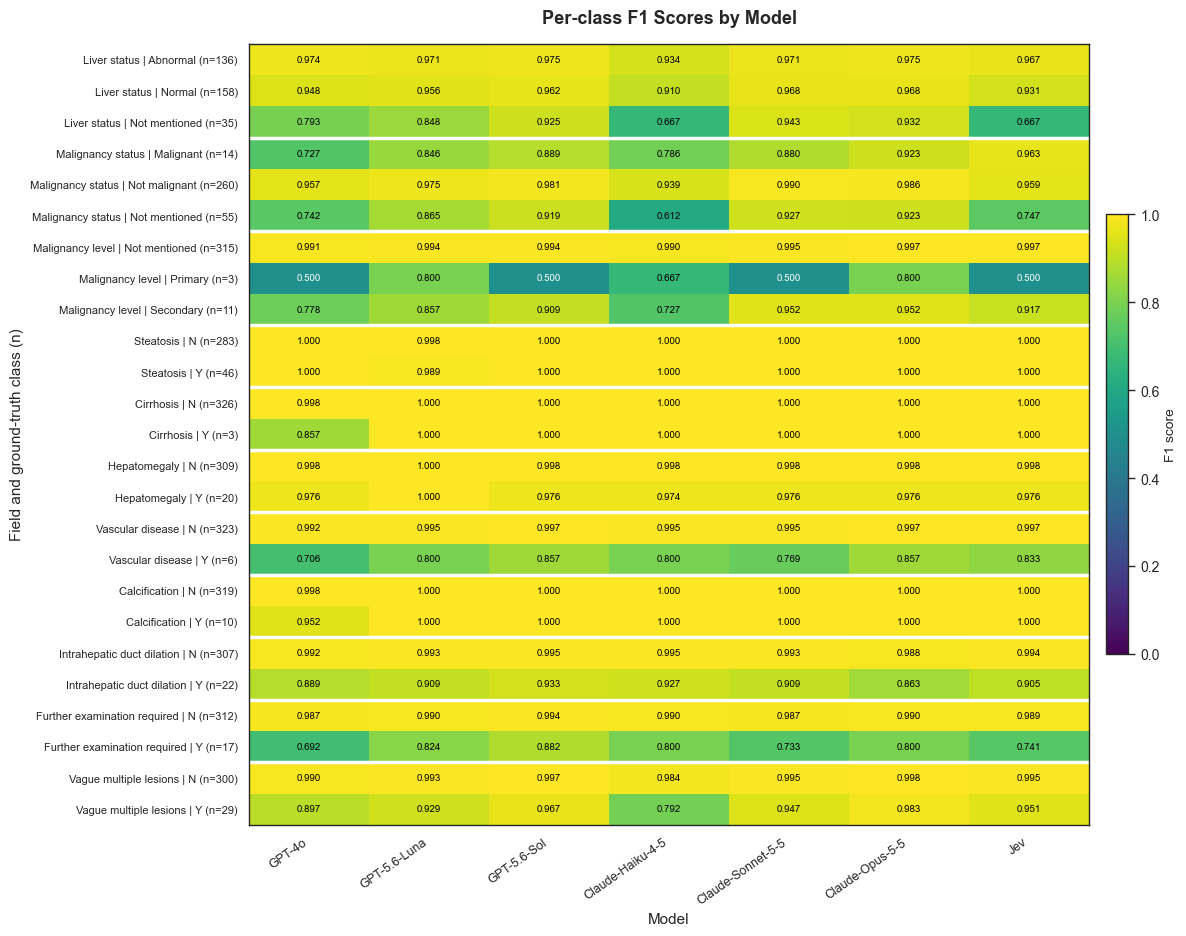


Per-class F1 analysis completed.
Results saved to: D:\F\HDF DATASET\Ct labels\13-Rerun again with temp 0 and tokens 8k\paper_results_consolidated
All available model pairs contain 11 fields.


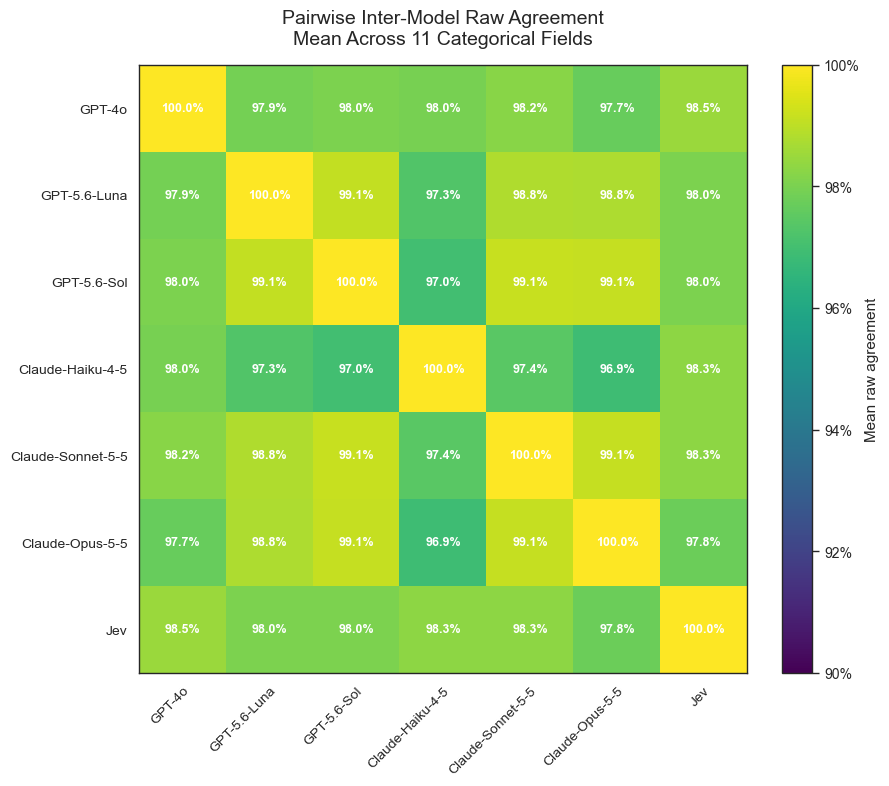

Saved to: paper_results_consolidated\figure_pairwise_mean_raw_agreement_heatmap.png
Final matrix dimensions: (7, 7)
All 21 unique model pairs are present.
All model pairs contain 11 categorical fields.
All model pairs have 11 valid kappa values.


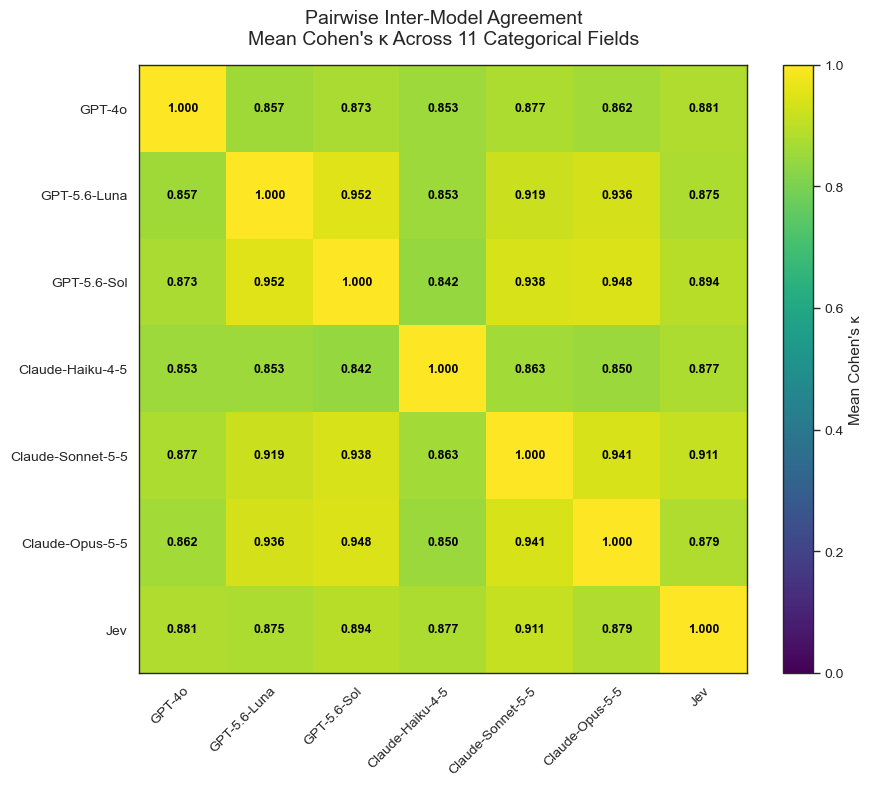


Saved to: paper_results_consolidated\figure_pairwise_mean_kappa_heatmap.png
Final matrix dimensions: (7, 7)


In [24]:
FIELD_DISPLAY = {
    "further_exam_required": "Further examination required",
    "hepatomegaly": "Hepatomegaly",
    "intrahepatic_duct_dilation": "Intrahepatic duct dilation",
    "liver_calcification": "Calcification",
    "liver_cirrhosis": "Cirrhosis",
    "liver_malignancy_level": "Malignancy level",
    "liver_malignancy_status": "Malignancy status",
    "liver_status": "Liver status",
    "liver_steatosis": "Steatosis",
    "liver_vague_multiple_present": "Vague multiple lesions",
    "liver_vascular_disease": "Vascular disease",
}

CLASS_DISPLAY = {
    "y": "Y",
    "n": "N",
    "normal": "Normal",
    "abnormal": "Abnormal",
    "not_mentioned": "Not mentioned",
    "malignant": "Malignant",
    "not_malignant": "Not malignant",
    "primary": "Primary",
    "secondary": "Secondary",
    INVALID_PREDICTION: "Invalid prediction",
}


def display_field(field):
    return FIELD_DISPLAY.get(field, field.replace("_", " ").title())


def display_class(cls):
    return CLASS_DISPLAY.get(str(cls), str(cls).replace("_", " ").title())


def annotate_heatmap(ax, dataframe, fontsize=8):
    """Write numeric values inside a heatmap using contrast-aware text."""
    for i in range(dataframe.shape[0]):
        for j in range(dataframe.shape[1]):
            value = dataframe.iloc[i, j]

            if np.isfinite(value):
                text_color = "white" if value < 0.55 else "black"
                label = f"{value:.3f}"
            else:
                text_color = "black"
                label = "NA"

            ax.text(
                j,
                i,
                label,
                ha="center",
                va="center",
                fontsize=fontsize,
                color=text_color,
            )



# ============================================================
# Figure 1: balanced-accuracy heatmap
# Including mean of 8 binary and 3 hierarchical fields
# ============================================================

HIERARCHICAL_FIELDS = [
    "liver_status",
    "liver_malignancy_status",
    "liver_malignancy_level",
]

BINARY_FIELDS = [
    f for f in CATEGORICAL_FIELDS
    if f not in HIERARCHICAL_FIELDS
]

assert len(BINARY_FIELDS) == 8, "Expected exactly 8 binary fields"
assert len(HIERARCHICAL_FIELDS) == 3

heat = field_performance.pivot(
    index="field", columns="model", values="balanced_accuracy"
).reindex(
    index=CATEGORICAL_FIELDS, columns=MODEL_ORDER
)

heat.loc["binary_average"] = heat.loc[BINARY_FIELDS].mean(
    axis=0, skipna=False
)

heat.loc["hierarchical_average"] = heat.loc[HIERARCHICAL_FIELDS].mean(
    axis=0, skipna=False
)

fig, ax = plt.subplots(figsize=(10, 8))

im = ax.imshow(
    heat.values,
    aspect="auto",
    vmin=0,
    vmax=1,
    cmap="viridis",
)

ax.set_xticks(range(len(MODEL_ORDER)))
ax.set_xticklabels(MODEL_ORDER, rotation=35, ha="right")

ax.set_yticks(range(len(heat)))
ax.set_yticklabels(
    [display_field(f) for f in CATEGORICAL_FIELDS]
    + [
        "Mean (8 binary fields)",
        "Mean (3 hierarchical fields)",
    ],
    fontsize=9,
)

annotate_heatmap(ax, heat, fontsize=8)

ax.axhline(
    y=len(CATEGORICAL_FIELDS) - 0.5,
    color="white",
    linewidth=2.5,
)

for label in ax.get_yticklabels()[-2:]:
    label.set_fontweight("bold")

fig.colorbar(im, ax=ax, label="Balanced accuracy")
ax.set_title("Balanced accuracy by field and model")
ax.set_xlabel("Model")
ax.set_ylabel("Field")

fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "figure1_balanced_accuracy_heatmap.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)


# ============================================================
# Supplement: Macro F1 heatmap
# Including mean of 8 binary and 3 hierarchical fields
# ============================================================

HIERARCHICAL_FIELDS = [
    "liver_status",
    "liver_malignancy_status",
    "liver_malignancy_level",
]

BINARY_FIELDS = [
    f for f in CATEGORICAL_FIELDS
    if f not in HIERARCHICAL_FIELDS
]

assert len(BINARY_FIELDS) == 8, "Expected exactly 8 binary fields"
assert len(HIERARCHICAL_FIELDS) == 3

heat_f1 = field_performance.pivot(
    index="field", columns="model", values="macro_f1"
).reindex(
    index=CATEGORICAL_FIELDS, columns=MODEL_ORDER
)

heat_f1.loc["binary_average"] = heat_f1.loc[BINARY_FIELDS].mean(
    axis=0, skipna=False
)

heat_f1.loc["hierarchical_average"] = heat_f1.loc[HIERARCHICAL_FIELDS].mean(
    axis=0, skipna=False
)

fig, ax = plt.subplots(figsize=(10, 8))

im = ax.imshow(
    heat_f1.values,
    aspect="auto",
    vmin=0,
    vmax=1,
    cmap="viridis",
)

ax.set_xticks(range(len(MODEL_ORDER)))
ax.set_xticklabels(MODEL_ORDER, rotation=35, ha="right")

ax.set_yticks(range(len(heat_f1)))
ax.set_yticklabels(
    [display_field(f) for f in CATEGORICAL_FIELDS]
    + [
        "Mean (8 binary fields)",
        "Mean (3 hierarchical fields)",
    ],
    fontsize=9,
)

annotate_heatmap(ax, heat_f1, fontsize=8)

ax.axhline(
    y=len(CATEGORICAL_FIELDS) - 0.5,
    color="white",
    linewidth=2.5,
)

# Emphasize summary row labels
for label in ax.get_yticklabels()[-2:]:
    label.set_fontweight("bold")

fig.colorbar(im, ax=ax, label="Macro F1")
ax.set_title("Macro F1 by field and model")
ax.set_xlabel("Model")
ax.set_ylabel("Field")

fig.tight_layout()
fig.savefig(
    OUTPUT_DIR / "supplement_macro_f1_heatmap.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)


# ============================================================
# Supplementary: Per-class F1-score heatmap
# With ground-truth class counts and field grouping
# ============================================================


required_columns = {
    "field", "class", "model", "f1", "n_reference"
}

missing = required_columns - set(per_class_metrics.columns)
if missing:
    raise ValueError(f"Missing columns: {missing}")

f1_plot = per_class_metrics[
    ["field", "class", "model", "f1", "n_reference"]
].copy()

# Check that each field/class/model combination is unique.
if f1_plot.duplicated(
    ["field", "class", "model"]
).any():
    raise ValueError(
        "Duplicate field/class/model combinations detected."
    )


ordered_rows = []
row_fields = []

for field in CATEGORICAL_FIELDS:

    field_classes = classes_in_reference(gt_cat[field])

    for cls in field_classes:

        n = int((gt_cat[field] == cls).sum())

        label = (
            f"{display_field(field)} | "
            f"{display_class(cls)} "
            f"(n={n})"
        )

        ordered_rows.append(label)
        row_fields.append(field)

f1_plot["field_class"] = f1_plot.apply(
    lambda r: (
        f"{display_field(r['field'])} | "
        f"{display_class(r['class'])} "
        f"(n={int(r['n_reference'])})"
    ),
    axis=1,
)


f1_pivot = (
    f1_plot
    .pivot(
        index="field_class",
        columns="model",
        values="f1",
    )
    .reindex(
        index=ordered_rows,
        columns=MODEL_ORDER,
    )
)

values = f1_pivot.to_numpy(dtype=float)

if np.isfinite(values).any():
    if (
        np.nanmin(values) < 0
        or np.nanmax(values) > 1
    ):
        raise ValueError("F1 scores must be between 0 and 1.")


print("\nPER-CLASS F1 SCORES")
print("=" * 80)

display(f1_pivot.round(3))

f1_pivot.to_csv(
    OUTPUT_DIR / "supplement_per_class_f1_scores.csv",
    float_format="%.3f",
    index_label="Field and class",
)


fig_height = max(8, 0.38 * len(f1_pivot))

fig, ax = plt.subplots(
    figsize=(12, fig_height)
)

im = ax.imshow(
    values,
    aspect="auto",
    interpolation="nearest",
    vmin=0,
    vmax=1,
    cmap="viridis",
)

ax.set_xticks(np.arange(len(MODEL_ORDER)))
ax.set_xticklabels(
    MODEL_ORDER,
    rotation=35,
    ha="right",
    fontsize=9,
)

ax.set_yticks(np.arange(len(f1_pivot)))
ax.set_yticklabels(
    f1_pivot.index,
    fontsize=8,
)

for i in range(f1_pivot.shape[0]):
    for j in range(f1_pivot.shape[1]):

        f1 = values[i, j]

        if np.isfinite(f1):
            label = f"{f1:.3f}"
            text_color = (
                "white" if f1 < 0.55 else "black"
            )
        else:
            label = "NA"
            text_color = "white"

        ax.text(
            j,
            i,
            label,
            ha="center",
            va="center",
            fontsize=7,
            color=text_color,
        )


for i in range(1, len(row_fields)):

    if row_fields[i] != row_fields[i - 1]:

        ax.axhline(
            y=i - 0.5,
            color="white",
            linewidth=2.5,
        )

cbar = fig.colorbar(
    im,
    ax=ax,
    fraction=0.025,
    pad=0.02,
)

cbar.set_label(
    "F1 score",
    fontsize=10,
)

ax.set_title(
    "Per-class F1 Scores by Model",
    fontsize=13,
    fontweight="bold",
    pad=15,
)

ax.set_xlabel("Model", fontsize=11)
ax.set_ylabel(
    "Field and ground-truth class (n)",
    fontsize=11,
)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "supplement_per_class_f1_heatmap.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

print("\nPer-class F1 analysis completed.")
print(f"Results saved to: {OUTPUT_DIR.resolve()}")





# ============================================================
# Mean pairwise raw agreement across 11 categorical fields
# Corrected 7 × 7 heatmap (including Jev)
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter


model_order = [
    "GPT-4o",
    "GPT-5.6-Luna",
    "GPT-5.6-Sol",
    "Claude-Haiku-4-5",
    "Claude-Sonnet-5-5",
    "Claude-Opus-5-5",
    "Jev"
]

df = intermodel_raw.copy()

df["model_a"] = df["model_a"].astype(str).str.strip()
df["model_b"] = df["model_b"].astype(str).str.strip()
df["model_a"] = df["model_a"].replace({
    "Jev1.14": "Jev",
    "JEV1.14": "Jev",
    "Jev 1.14": "Jev"
})

df["model_b"] = df["model_b"].replace({
    "Jev1.14": "Jev",
    "JEV1.14": "Jev",
    "Jev 1.14": "Jev"
})

df = df[
    df["model_a"].isin(model_order) &
    df["model_b"].isin(model_order)
].copy()

df["raw_agreement"] = pd.to_numeric(
    df["raw_agreement"], errors="coerce"
)

if df["raw_agreement"].dropna().gt(1).any():
    raise ValueError(
        "raw_agreement must be between 0 and 1, "
        "not between 0 and 100."
    )

# ------------------------------------------------------------
# 1. Average raw agreement across categorical fields
# ------------------------------------------------------------

df["pair"] = df.apply(
    lambda row: tuple(sorted([
        row["model_a"], row["model_b"]
    ])),
    axis=1
)

df = df[df["model_a"] != df["model_b"]].copy()

pairwise_mean_raw = (
    df.groupby("pair")
    .agg(
        mean_raw_agreement=("raw_agreement", "mean"),
        n_fields=("field", "nunique")
    )
    .reset_index()
)

pairwise_mean_raw[["model_a", "model_b"]] = (
    pd.DataFrame(
        pairwise_mean_raw["pair"].tolist(),
        index=pairwise_mean_raw.index
    )
)

expected_pairs = len(model_order) * (len(model_order) - 1) // 2

if len(pairwise_mean_raw) != expected_pairs:
    print(
        f"WARNING: Found {len(pairwise_mean_raw)} "
        f"of {expected_pairs} expected model pairs."
    )

if not (pairwise_mean_raw["n_fields"] == 11).all():
    print(
        "WARNING: Some model pairs do not contain "
        "exactly 11 categorical fields."
    )
else:
    print("All available model pairs contain 11 fields.")

raw_matrix = pd.DataFrame(
    np.nan,
    index=model_order,
    columns=model_order,
    dtype=float
)

np.fill_diagonal(raw_matrix.values, 1.0)

for _, row in pairwise_mean_raw.iterrows():

    m1 = row["model_a"]
    m2 = row["model_b"]
    agreement = row["mean_raw_agreement"]

    raw_matrix.loc[m1, m2] = agreement
    raw_matrix.loc[m2, m1] = agreement

missing = [
    (model_order[i], model_order[j])
    for i in range(7)
    for j in range(i + 1, 7)
    if pd.isna(raw_matrix.iloc[i, j])
]

if missing:
    print("WARNING: Missing model pairs:")
    for pair in missing:
        print(pair)

fig, ax = plt.subplots(figsize=(10, 8))

im = ax.imshow(
    raw_matrix.to_numpy(),
    cmap="viridis",
    vmin=0.90,
    vmax=1.00,
    interpolation="nearest",
    aspect="equal"
)

n_models = len(model_order)

ax.set_xticks(np.arange(n_models))
ax.set_yticks(np.arange(n_models))

ax.set_xticklabels(
    model_order,
    rotation=45,
    ha="right",
    rotation_mode="anchor",
    fontsize=10
)

ax.set_yticklabels(
    model_order,
    fontsize=10
)

# Explicit limits prevent extra displayed cells
ax.set_xlim(-0.5, n_models - 0.5)
ax.set_ylim(n_models - 0.5, -0.5)

ax.set_title(
    "Pairwise Inter-Model Raw Agreement\n"
    "Mean Across 11 Categorical Fields",
    fontsize=14,
    pad=15
)


for i in range(n_models):
    for j in range(n_models):

        value = raw_matrix.iloc[i, j]

        if pd.notna(value):

            ax.text(
                j,
                i,
                f"{value * 100:.1f}%",
                ha="center",
                va="center",
                color="white",
                fontsize=9,
                fontweight="bold"
            )

cbar = fig.colorbar(
    im,
    ax=ax,
    fraction=0.046,
    pad=0.04
)

cbar.set_label(
    "Mean raw agreement",
    fontsize=11
)

cbar.set_ticks(
    np.arange(0.90, 1.001, 0.02)
)

cbar.ax.yaxis.set_major_formatter(
    PercentFormatter(xmax=1, decimals=0)
)


plt.tight_layout()

output_path = (
    OUTPUT_DIR /
    "figure_pairwise_mean_raw_agreement_heatmap.png"
)

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print(f"Saved to: {output_path}")
print(f"Final matrix dimensions: {raw_matrix.shape}")



# ============================================================
# Mean pairwise Cohen's kappa across 11 categorical fields
# Corrected 7 × 7 heatmap (including Jev)
# ============================================================


model_order = [
    "GPT-4o",
    "GPT-5.6-Luna",
    "GPT-5.6-Sol",
    "Claude-Haiku-4-5",
    "Claude-Sonnet-5-5",
    "Claude-Opus-5-5",
    "Jev"
]

df = intermodel_kappa.copy()

df["model_a"] = df["model_a"].astype(str).str.strip()
df["model_b"] = df["model_b"].astype(str).str.strip()

jev_aliases = {
    "Jev1.14": "Jev",
    "JEV1.14": "Jev",
    "Jev 1.14": "Jev",
    "JEV 1.14": "Jev"
}

df["model_a"] = df["model_a"].replace(jev_aliases)
df["model_b"] = df["model_b"].replace(jev_aliases)

df = df[
    df["model_a"].isin(model_order) &
    df["model_b"].isin(model_order)
].copy()

df["kappa"] = pd.to_numeric(
    df["kappa"],
    errors="coerce"
)

invalid_kappa = df["kappa"].notna() & ~df["kappa"].between(-1, 1)

if invalid_kappa.any():
    raise ValueError(
        "Cohen's kappa values must be between -1 and 1."
    )

df["pair"] = df.apply(
    lambda row: tuple(sorted([
        row["model_a"],
        row["model_b"]
    ])),
    axis=1
)

df = df[df["model_a"] != df["model_b"]].copy()

duplicate_mask = df.duplicated(
    subset=["pair", "field"],
    keep=False
)

if duplicate_mask.any():
    raise ValueError(
        "Duplicate model-pair/field records detected. "
        "Check whether A-B and B-A are both present, "
        "or whether fields were repeated."
    )

pairwise_mean_kappa = (
    df.groupby("pair")
    .agg(
        mean_kappa=("kappa", "mean"),
        n_fields=("field", "nunique"),
        n_valid_kappa=("kappa", "count")
    )
    .reset_index()
)

pairwise_mean_kappa[["model_a", "model_b"]] = (
    pd.DataFrame(
        pairwise_mean_kappa["pair"].tolist(),
        index=pairwise_mean_kappa.index
    )
)

n_models = len(model_order)

expected_pairs = n_models * (n_models - 1) // 2

if len(pairwise_mean_kappa) != expected_pairs:
    print(
        f"WARNING: Found {len(pairwise_mean_kappa)} "
        f"of {expected_pairs} expected model pairs."
    )
else:
    print("All 21 unique model pairs are present.")

invalid_fields = pairwise_mean_kappa[
    pairwise_mean_kappa["n_fields"] != 11
]

if not invalid_fields.empty:
    print(
        "WARNING: Some model pairs do not contain "
        "exactly 11 categorical fields."
    )
    print(invalid_fields[
        ["model_a", "model_b", "n_fields"]
    ].to_string(index=False))
else:
    print("All model pairs contain 11 categorical fields.")

invalid_counts = pairwise_mean_kappa[
    pairwise_mean_kappa["n_valid_kappa"] != 11
]

if not invalid_counts.empty:
    print(
        "WARNING: Some pairs have missing or undefined "
        "kappa values. Their means use fewer than 11 fields."
    )
    print(invalid_counts[
        ["model_a", "model_b", "n_valid_kappa"]
    ].to_string(index=False))
else:
    print("All model pairs have 11 valid kappa values.")


kappa_matrix = pd.DataFrame(
    np.nan,
    index=model_order,
    columns=model_order,
    dtype=float
)

np.fill_diagonal(kappa_matrix.values, 1.0)

for _, row in pairwise_mean_kappa.iterrows():

    m1 = row["model_a"]
    m2 = row["model_b"]
    k = row["mean_kappa"]

    kappa_matrix.loc[m1, m2] = k
    kappa_matrix.loc[m2, m1] = k

missing_pairs = [
    (model_order[i], model_order[j])
    for i in range(n_models)
    for j in range(i + 1, n_models)
    if pd.isna(kappa_matrix.iloc[i, j])
]

if missing_pairs:
    print("WARNING: Missing or undefined model pairs:")
    for pair in missing_pairs:
        print(pair)


fig, ax = plt.subplots(figsize=(10, 8))

off_diagonal = kappa_matrix.to_numpy().copy()

np.fill_diagonal(off_diagonal, np.nan)

valid_values = off_diagonal[np.isfinite(off_diagonal)]

if valid_values.size > 0:
    lower_limit = min(0.0, float(valid_values.min()))
else:
    lower_limit = 0.0

cmap = plt.get_cmap("viridis").copy()
cmap.set_bad(color="#E6E6E6")

im = ax.imshow(
    np.ma.masked_invalid(kappa_matrix.to_numpy()),
    cmap=cmap,
    vmin=lower_limit,
    vmax=1.0,
    interpolation="nearest",
    aspect="equal"
)

ax.set_xticks(np.arange(n_models))
ax.set_yticks(np.arange(n_models))

ax.set_xticklabels(
    model_order,
    rotation=45,
    ha="right",
    rotation_mode="anchor",
    fontsize=10
)

ax.set_yticklabels(
    model_order,
    fontsize=10
)

ax.set_xlim(-0.5, n_models - 0.5)
ax.set_ylim(n_models - 0.5, -0.5)

ax.set_title(
    "Pairwise Inter-Model Agreement\n"
    "Mean Cohen's \u03ba Across 11 Categorical Fields",
    fontsize=14,
    pad=15
)

for i in range(n_models):
    for j in range(n_models):

        value = kappa_matrix.iloc[i, j]

        if pd.notna(value):
            rgba = im.cmap(im.norm(value))

            luminance = (
                0.2126 * rgba[0] +
                0.7152 * rgba[1] +
                0.0722 * rgba[2]
            )

            text_color = (
                "black" if luminance > 0.6 else "white"
            )

            ax.text(
                j,
                i,
                f"{value:.3f}",
                ha="center",
                va="center",
                color=text_color,
                fontsize=9,
                fontweight="bold"
            )


cbar = fig.colorbar(
    im,
    ax=ax,
    fraction=0.046,
    pad=0.04
)

cbar.set_label(
    "Mean Cohen's \u03ba",
    fontsize=11
)

cbar.ax.tick_params(labelsize=10)

plt.tight_layout()

output_dir = Path(OUTPUT_DIR)
output_dir.mkdir(parents=True, exist_ok=True)

output_path = (
    output_dir /
    "figure_pairwise_mean_kappa_heatmap.png"
)

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print(f"\nSaved to: {output_path}")
print(f"Final matrix dimensions: {kappa_matrix.shape}")
